<a href="https://colab.research.google.com/github/hagopjay/x3d.lab/blob/main/notebooks/unreal/07_Unreal_Fidelity.002_completesL4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<a href="https://colab.research.google.com/github/hagopjay/x3d.lab/blob/main/notebooks/unreal/07_Unreal_Fidelity.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# x3d.lab · 07 Unreal Fidelity: X3D scenes as Unreal Engine stills, on a Colab GPU, with no screen

**Goal:** bring impressive X3D scenes into **Unreal Engine 5** conclusively and robustly, render the highest-fidelity stills this GPU allows, and *measure* what arrived and how it looks next to X_ITE and Blender Cycles. Streaming is not part of this notebook.

1. **knows its GPU**: model, VRAM, driver, CUDA, vCPUs, RAM, disk; looks up what the GPU can do (RT cores, video encoder) and then asks the **Vulkan device itself** whether it can ray trace;
2. **gives Unreal real Vulkan**: Colab ships NVIDIA's compute driver only; we unpack the graphics half at exactly the driver's version (the route confirmed on a Colab A100, 10 Nov 2026);
3. **gets the engine from *you***: Epic's licence means you download Unreal with your own Epic account (one time, see below); the notebook copies it from your Drive, trims it, and can cache it there for next time;
4. **proves from Unreal's own log** that it rendered with Vulkan on the NVIDIA GPU, not on NullRHI or a software rasterizer;
5. **imports** each scene: X3D → glTF by the lab's Blender leg (`x3dlab.formats`, owned by notebook 06 Foundry), glTF → Unreal by Interchange in a one-shot editor task, then **accounts** for it: meshes, triangles, materials, textures, lights, cameras, instancing, axes, units, light units, field of view;
6. **renders** every X3D viewpoint through a ladder (*preview / high / ultra*) with Movie Render Queue: Lumen everywhere, hardware ray tracing and the **path tracer** where the GPU has RT cores, big resolutions and resident texture pools where it has VRAM;
7. **compares** Unreal with X_ITE (and Cycles) on the same views with the lab's own referee (`formats.match`, `compare_pngs`), plus SSIM, in a contact sheet;
8. ends with a **scorecard** (PASS / WARN / FAIL / SKIP, a reason on every row), a JSON **run card**, and everything saved to your Drive.

| Colab GPU | What Unreal gets | Use it for |
|---|---|---|
| **G4** (RTX PRO 6000 Blackwell, 96 GB) | RT cores **and** the most VRAM: hardware ray tracing, the path tracer, 8K stills | **the best Colab GPU for Unreal fidelity** |
| **A100** (40 / 80 GB) | **no RT cores, no NVENC**: software Lumen only, no path tracer; but huge VRAM: 8K stills without tiling, resident texture pools | big stills, big scenes |
| **L4** (24 GB) | RT cores (Ada), path tracer, 4K | good value |
| **T4** (16 GB) | RT cores (Turing), but small RAM and few vCPUs on the standard runtime: the first shader compile can take hours | a smoke test; use *High-RAM* |

**Runtime:** *Runtime › Change runtime type* › **G4** (best), A100 or L4. **Time:** the first run pays a large one-time cost (copying ~40 GB, compiling Unreal's shaders); later runs reuse what this notebook caches in your Drive. Everything was tested in a sandbox *without* a GPU or Unreal: this notebook's first Colab run is the live test, so it explains every failure in detail.

<details><summary><b>📖 Words used here</b> (click)</summary>

| Word | Meaning |
|---|---|
| **RHI** | Unreal's *Rendering Hardware Interface*: the layer that talks to Vulkan, DirectX or Metal. **NullRHI** draws nothing |
| **Vulkan ICD** | the small JSON file that tells Vulkan which GPU driver library to load |
| **Lumen** | Unreal's dynamic global illumination and reflections; *software* Lumen runs on any GPU, *hardware* Lumen uses RT cores |
| **path tracer** | Unreal's offline-quality renderer: needs hardware ray tracing |
| **Movie Render Queue (MRQ)** | Unreal's tool for final-quality frames: many samples per pixel, EXR/PNG output |
| **Interchange** | Unreal's import framework (glTF, FBX, USD) |
| **DDC** | *Derived Data Cache*: compiled shaders and cooked data, cached so the second run is fast |
| **EV100**, **lux**, **candela** | exposure, illuminance (directional lights) and luminous intensity (point and spot lights): Unreal's physical units |
| **NVENC** | NVIDIA's video encoder (Pixel Streaming needs it; the A100 has none) |
</details>

Status words: **PASS** worked as expected · **WARN** worked, worth a look · **FAIL** did not work · **SKIP** not run (the reason is shown).

## Your one-time step: get Unreal Engine with your Epic account

This notebook cannot download Unreal for you (Epic's EULA: each user downloads it with their own account). Do **one** of these once; the notebook finds it by itself.

**A · The Linux zip in your Google Drive (recommended).**
1. Sign in at [unrealengine.com/linux](https://www.unrealengine.com/linux) with your Epic account and accept the EULA.
2. Download **`Linux_Unreal_Engine_5.8.4.zip`** (the current release in Nov 2026; 5.8.1's zip was 39 GB, ~70 GB unpacked). 5.9 is a *preview*: use it only on purpose.
3. Upload the zip to your Drive folder **`MyDrive/x3dlab/unreal/`** (any name `Linux_Unreal_Engine_*.zip`). Drive needs the room (a Google One plan); the browser upload of 40 GB takes a while: let it finish.

**A2 · Straight from Epic's download link into your Drive (fastest: ~70 MB/s, no upload from your computer).** On unrealengine.com/linux, right-click the download button and copy the link, then run step **5a** below and paste it when asked. The link is typed into a hidden prompt: it is never saved in the notebook, so saving the notebook to GitHub cannot publish it (Epic's links expire after an hour anyway).

**B · Epic's container image, without Docker.**
1. Link your GitHub account to your Epic account ([epicgames.com › Account › Apps and accounts](https://www.epicgames.com/account/connections)) and accept the e-mail invitation to GitHub's **EpicGames** organisation.
2. Create a GitHub *classic* personal access token with only **`read:packages`**.
3. In Colab's 🔑 Secrets add **`GHCR_USER`** (your GitHub user name) and **`GHCR_TOKEN`** (the token), with *Notebook access* on.
4. Set `ENGINE_SOURCE = ghcr` and `GHCR_TAG = dev-slim-5.8.4` below. (The 5.8.1 dev-slim image held a 1 TB build-cache file; this notebook skips it, and Epic fixed it by 5.8.3.)

After the first successful run, `CACHE_ENGINE` writes a trimmed engine archive (no debug symbols, templates or samples: what Epic's own *dev-slim* image also leaves out) to `MyDrive/x3dlab/unreal/cache/`, and later runs start from that. It is your own copy in your own Drive; do not share it.

In [3]:
#@title 1 · Options { display-mode: "form" }
ENGINE_SOURCE = "auto"  #@param ["auto", "cache", "zip", "ghcr"]
ENGINE_VERSION = "5.4"  #@param ["5.4", "5.8", "5.9", "5.2", "newest"] {allow-input: true}
#@markdown **ENGINE_VERSION** picks among the engines in your Drive (cache archives and `Linux_Unreal_Engine_*.zip`): `5.4` = any 5.4.x, `5.8.4` = exactly that, `newest` = the newest that is not a preview. Changing it switches engines (the one on the local disk is replaced). 5.4 is the default because it is the newest *stable* Linux zip seen so far; 5.9 is a preview.
DRIVE_DIR = "/content/drive/MyDrive/x3dlab/unreal"  #@param {type:"string"}
GHCR_TAG = "dev-slim-5.8.4"  #@param {type:"string"}
SCENES = "calib, stilllife, toycar-x3d, toycar-gltf, odyssey, gobbler3"  #@param {type:"string"}
#@markdown also available: `gobbler-gyro`, `hall` (14 MB, 23 viewpoints), `pbr-tests`, `lantern-gltf`, `waterbottle-gltf`
RUNG = "auto"  #@param ["auto", "preview", "high", "ultra", "ultra_lumen"]
LOOK = "cinematic"  #@param ["cinematic", "match"]
MAX_VIEWPOINTS = 4  #@param {type:"slider", min:1, max:30, step:1}
COMPARE = True  #@param {type:"boolean"}
USD = "auto"  #@param ["auto", "off"]
CACHE_ENGINE = True  #@param {type:"boolean"}
CACHE_DDC = True  #@param {type:"boolean"}
FORCE_HWRT = False  #@param {type:"boolean"}
VERBOSE = True  #@param {type:"boolean"}
VISUAL = True  #@param {type:"boolean"}
HEARTBEAT_S = 20  #@param {type:"slider", min:5, max:120, step:5}
#@markdown **VERBOSE** streams Unreal's important log lines while it runs, plus a heartbeat every `HEARTBEAT_S` seconds (shader jobs and their rate, workers, Unreal's memory, RAM, VRAM, GPU %, free disk), and warns when Unreal's memory grows with nothing to show for it. **VISUAL** shows every still the moment it is written and a VRAM/GPU chart after each Unreal job.
LAB_REPO = "hagopjay/x3d.lab"
LAB_REF = "main"
#@markdown **auto** rung: *high* on a T4 or L4, *ultra* on A100 / G4. **match** look = X3D-like light (no tone curve, no global illumination): use it to compare engines; **cinematic** = Lumen GI, filmic tone curve.
print("✅ options saved: engine from %s · scenes %s · rung %s · look %s" % (ENGINE_SOURCE, SCENES, RUNG, LOOK))

✅ options saved: engine from auto · scenes calib, stilllife, toycar-x3d, toycar-gltf, odyssey, gobbler3 · rung auto · look cinematic


## 2 · The helpers

Two pieces of code, both from this repository: the Unreal leg (`notebooks/unreal/x3due`, plus the Unreal project and the Python scripts that run *inside* Unreal), and the merged `x3dlab` package for everything that is not Unreal (the X3D → glTF trip and its referee, X_ITE in headless Chrome, Blender).

In [4]:
#@title 2 · Get the helpers { display-mode: "form" }
import importlib, json, os, subprocess, sys, time
from pathlib import Path
from IPython.display import HTML, Image as IPImage, display

def sh(cmd, timeout=1800):
    r = subprocess.run(cmd, shell=isinstance(cmd, str), capture_output=True, text=True, timeout=timeout)
    return (r.stdout + r.stderr).strip()

def git(args, timeout=1800):
    """git with a read-only token from Colab Secrets (GITHUB_TOKEN) sent as a header for this repo only, the same way as
    notebooks 01-06: works when the repo is private; the token never goes into a URL, a file or the output."""
    env = dict(os.environ)
    try:
        from google.colab import userdata
        token = userdata.get("GITHUB_TOKEN")
    except Exception:
        token = os.environ.get("GITHUB_TOKEN")
    if token:
        import base64
        env.update(GIT_CONFIG_COUNT="1", GIT_CONFIG_KEY_0="http.https://github.com/%s.extraheader" % LAB_REPO,
                   GIT_CONFIG_VALUE_0="AUTHORIZATION: basic " + base64.b64encode(("x-access-token:" + token).encode()).decode())
    r = subprocess.run(["git"] + args, capture_output=True, text=True, timeout=timeout, env=env)
    return r.returncode, (r.stdout + r.stderr).strip()

LAB_DIR = Path("/content/x3d.lab") if Path("/content").is_dir() else Path.home() / "x3d.lab"
if os.environ.get("X3DLAB_DEV") and Path(os.environ["X3DLAB_DEV"]).is_dir():
    LAB_DIR = Path(os.environ["X3DLAB_DEV"])                     # a local checkout
elif not (LAB_DIR / ".git").exists():
    rc, msg = git(["clone", "-q", "--depth", "1", "--branch", LAB_REF, "https://github.com/%s" % LAB_REPO, str(LAB_DIR)])
    if rc:
        raise SystemExit("%s\ncould not clone github.com/%s. If that repo is private, add a read-only GitHub token as the Colab "
                         "secret GITHUB_TOKEN (key icon, left bar) and allow this notebook to read it." % (msg, LAB_REPO))
else:
    rc, msg = git(["-C", str(LAB_DIR), "pull", "-q", "--ff-only"])
    print(msg or "helpers up to date")
UNREAL_DIR = LAB_DIR / "notebooks" / "unreal"
sys.path.insert(0, str(UNREAL_DIR))
if importlib.util.find_spec("x3dlab") is None:
    print("installing the x3dlab package (formats, Blender, X_ITE)…")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-e", "%s[research]" % LAB_DIR], check=True)
# An editable install only becomes importable after a kernel restart (its .pth file is read at start-up), so put the
# package's source folder on the path as well: `import x3dlab` works in this same session.
if str(LAB_DIR / "src") not in sys.path:
    sys.path.insert(1, str(LAB_DIR / "src"))
importlib.invalidate_caches()
from x3due import (compare, convert, engine, engines, gltfstat, live, pipeline, project, report, showcase, tier, staging, uerun, vulkan,
                   x3dscene)
SC = report.Scorecard()
CARD = {"notebook": "07_Unreal_Fidelity", "lab_commit": sh("git -C %s rev-parse --short HEAD" % LAB_DIR), "options": {
    k: globals()[k] for k in ("ENGINE_SOURCE", "ENGINE_VERSION", "GHCR_TAG", "SCENES", "RUNG", "LOOK", "MAX_VIEWPOINTS", "COMPARE", "USD", "FORCE_HWRT")}}
WORK = Path("/content/x3due") if Path("/content").is_dir() else Path.home() / "x3due"
print("✅ helpers from %s @ %s · work folder %s" % (LAB_REPO, CARD["lab_commit"], WORK))

installing the x3dlab package (formats, Blender, X_ITE)…
✅ helpers from hagopjay/x3d.lab @ bdd9857 · work folder /content/x3due


## 3 · Which GPU is this, and what can it do for Unreal?

The table is from NVIDIA's own documents (sources in `x3due/tier.py` and `FINDINGS.md`). It is only a *prior*: step 4 asks the Vulkan device for its ray-tracing extensions, and that answer decides.

In [5]:
#@title 3 · Detect the tier { display-mode: "form" }
HW = tier.detect()
g = HW["gpu"]
print("GPU      :", ("%s · %.0f GB · driver %s · CUDA %s · compute %s" % (g["name"], HW["vram_gb"], HW["driver"], HW["cuda"], g["compute_cap"])) if g else "none")
print("machine  : %d vCPUs · %.0f GB RAM (%.0f free) · %.0f GB free disk in %s" % (HW["cpus"], HW.get("ram_gb", 0), HW.get("ram_available_gb", 0), HW["disk_free_gb"], HW["disk_path"]))
print("container: NVIDIA_DRIVER_CAPABILITIES=%s" % (HW["driver_capabilities"] or "(unset)"))
display(HTML("<div style='font-size:12.5px'>%s</div>" % tier.capability_table_markdown().replace("\n", "<br>")))
CARD["hardware"] = HW
if not g:
    SC.add("3 tier", "NVIDIA GPU present", "FAIL", "no nvidia-smi output: pick a GPU runtime (G4, A100, L4)")
else:
    SC.add("3 tier", "NVIDIA GPU present", "PASS", "%s, %.0f GB, driver %s" % (g["name"], HW["vram_gb"], HW["driver"]))
    SC.add("3 tier", "GPU in the capability table", "PASS" if HW["kind"] in tier.CAPS else "WARN",
           "%s: %s" % (HW["kind"], tier.CAPS.get(HW["kind"], {}).get("rt_note", "unknown GPU, ray tracing decided by Vulkan only")))
need = 90
SC.add("3 tier", "free disk for the engine", "PASS" if HW["disk_free_gb"] >= need else "WARN",
       "%.0f GB free; zip + trimmed engine need about %d GB (less when extracting straight from Drive)" % (HW["disk_free_gb"], need))
SC.add("3 tier", "RAM", "PASS" if HW.get("ram_gb", 0) >= 32 else "WARN",
       "%.0f GB (Unreal recommends 32 GB; shader workers are capped by RAM)" % HW.get("ram_gb", 0))

GPU      : NVIDIA L4 · 22 GB · driver 580.82.07 · CUDA 13.0 · compute 8.9
machine  : 12 vCPUs · 53 GB RAM (51 free) · 235 GB free disk in /content
container: NVIDIA_DRIVER_CAPABILITIES=compute,utility


'PASS'

In [8]:
!nvidia-smi; ls -la /dev/nvidia* 2>&1 | head; echo; python -c "import torch; print('CUDA:', torch.cuda.is_available())"

Wed Nov 11 17:30:33 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA L4                      Off |   00000000:00:03.0 Off |                    0 |
| N/A   38C    P8             12W /   72W |       0MiB /  23034MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## 4 · Give Unreal real Vulkan

Colab starts the container with `NVIDIA_DRIVER_CAPABILITIES=compute,utility`: CUDA works, Vulkan does not. `apt-get install libnvidia-gl-<branch>` fails here (*held broken packages*: it would replace Colab's CUDA userspace). What works, and what this cell does: **download** `libnvidia-gl`, `libnvidia-gpucomp` and `libnvidia-common` at *exactly* the driver's version, **unpack** their files (`dpkg -x`, apt's database untouched), `ldconfig`, install `vulkan-tools`. It never installs a different driver version and never hand-writes an ICD file. Then it asks Vulkan, *as the user Unreal will run as*, what the device can do.

In [6]:
#@title 4 · Vulkan driver, device and ray-tracing extensions { display-mode: "form" }
VK_ENABLE = vulkan.enable()
print("driver %s · %s" % (VK_ENABLE.get("driver"), VK_ENABLE.get("skipped") or "unpacked: " + ", ".join("%s=%s" % kv for kv in VK_ENABLE.get("plan", {}).get("packages", {}).items())))
for d in VK_ENABLE.get("done", []):
    print("  %s → rc %s %s" % (d["cmd"], d["rc"], d["err"][-120:] if d["rc"] else ""))
if HW["gpu"]:
    uerun.ensure_user("ue", [])        # Unreal refuses root; Vulkan is asked as the same user Unreal will run as
VK = vulkan.probe(user="ue" if HW["gpu"] else None)
for d in VK["devices"]:
    print("Vulkan device: %s · %s · API %s%s" % (d.get("deviceName"), d.get("driverName"), d.get("apiVersion"), " (software!)" if d["software"] else ""))
PLAN = tier.plan(HW, VK, force_hwrt=FORCE_HWRT)
rt = PLAN["ray_tracing"]
print("ray tracing:", rt["why"])
print("extensions :", ", ".join("%s %s" % (k, "✓" if v else "✗") for k, v in rt["extensions"].items()))
for n in PLAN["notes"]:
    print("→", n)
st = vulkan.status()
SC.add("4 Vulkan", "NVIDIA Vulkan ICD present", "PASS" if st["nvidia_icd"] else "FAIL",
       st["nvidia_icd"][0] if st["nvidia_icd"] else (VK_ENABLE.get("skipped") or VK_ENABLE.get("error") or "no nvidia_icd.json"))
nv = VK["nvidia_device"]
SC.add("4 Vulkan", "user ue sees the NVIDIA device", "PASS" if nv and not nv["software"] else "FAIL",
       "%s (Vulkan %s)" % (nv.get("deviceName"), nv.get("apiVersion")) if nv else "vulkaninfo as ue lists %s" % ([d.get("deviceName") for d in VK["devices"]] or "nothing"))
SC.add("4 Vulkan", "ray tracing decision", rt["status"], rt["why"])
SC.add("4 Vulkan", "nvoptix.bin (OptiX denoiser)", "PASS" if st["nvoptix_bin"] else "WARN", st["nvoptix_bin"][0] if st["nvoptix_bin"] else "missing: Cycles falls back to OpenImageDenoise")
CARD.update(vulkan={"enable": {k: VK_ENABLE.get(k) for k in ("driver", "skipped", "plan", "error")}, "devices": [
    {k: v for k, v in d.items() if k != "extensions"} for d in VK["devices"]]}, plan={k: v for k, v in PLAN.items() if k != "ladder"},
    ladder=PLAN["ladder"])

driver 580.82.07 · unpacked: libnvidia-gl-580=580.82.07-0ubuntu1, libnvidia-gpucomp-580=580.82.07-0ubuntu1, libnvidia-common-580=580.82.07-0ubuntu1
  apt-get download libnvidia-gl-580=580.82.07-0ubuntu1 libnvidia-gpucomp-580=580.82.07-0ubuntu1 libnvidia-common-580=580.82.07-0ubuntu1 → rc 0 
  dpkg -x libnvidia-common-580_580.82.07-0ubuntu1_all.deb / → rc 0 
  dpkg -x libnvidia-gl-580_580.82.07-0ubuntu1_amd64.deb / → rc 0 
  dpkg -x libnvidia-gpucomp-580_580.82.07-0ubuntu1_amd64.deb / → rc 0 
  apt-get install vulkan-tools → rc 0 
Vulkan device: NVIDIA L4 · NVIDIA · API 1.4.312
ray tracing: device lists VK_KHR_ray_tracing_pipeline + VK_KHR_acceleration_structure
extensions : VK_KHR_ray_tracing_pipeline ✓, VK_KHR_acceleration_structure ✓, VK_KHR_ray_query ✓, VK_KHR_ray_tracing_position_fetch ✓, VK_KHR_deferred_host_operations ✓


In [7]:
#@title 4b · Vulkan for THIS GPU: diagnose, and repair from NVIDIA's own driver package { display-mode: "form" }
import glob, json, os, re, shutil, subprocess, urllib.request
def sh(c, t=900):
    r = subprocess.run(c, shell=True, capture_output=True, text=True, timeout=t)
    return (r.stdout + r.stderr).strip()
def ue_sees_gpu():
    out = sh("runuser -u ue -- env -i HOME=/home/ue PATH=/usr/bin:/bin vulkaninfo --summary 2>&1")
    return ("NVIDIA" in out and "llvmpipe" not in out.split("deviceName")[-1]), out
#ver, name = [x.strip() for x in sh("nvidia-smi --query-gpu=driver_version,name --format=csv,noheader").split(",")[:2]]
smi = sh("nvidia-smi --query-gpu=driver_version,name --format=csv,noheader")
assert "," in smi, "nvidia-smi says: %s\n→ no GPU on this runtime: Runtime › Change runtime type › T4 GPU, then reconnect" % smi[:300]
ver, name = [x.strip() for x in smi.split(",")[:2]]
print("GPU %s · driver %s" % (name, ver))
if "VK_ENABLE" in globals():
    print("step 4 said:", {k: VK_ENABLE.get(k) for k in ("driver", "skipped", "error")})
sh("id ue || useradd -m ue")
if not shutil.which("vulkaninfo"):
    sh("apt-get install -y -qq libvulkan1 vulkan-tools || (apt-get update -qq && apt-get install -y -qq libvulkan1 vulkan-tools)")
print("ICD files:", glob.glob("/usr/share/vulkan/icd.d/*nvidia*") + glob.glob("/etc/vulkan/icd.d/*nvidia*") or "none")
ok, out = ue_sees_gpu()
if ok:
    print("✅ user ue already sees the GPU through Vulkan: nothing to repair")
else:
    print("user ue does not see the GPU (%s): installing the Vulkan/GL userspace of driver %s from NVIDIA" % (
        (re.findall(r"ERROR[^\n]*", out) or ["no NVIDIA device"])[0][:120], ver))
    run = "/content/NVIDIA-Linux-x86_64-%s.run" % ver
    for url in ("https://us.download.nvidia.com/tesla/%s/NVIDIA-Linux-x86_64-%s.run" % (ver, ver),
                "https://download.nvidia.com/XFree86/Linux-x86_64/%s/NVIDIA-Linux-x86_64-%s.run" % (ver, ver)):
        if os.path.exists(run) and os.path.getsize(run) > 50e6:
            break
        try:
            print("  downloading", url.split("/")[2], "…")
            urllib.request.urlretrieve(url, run)
        except Exception as e:
            print("  ", e)
    assert os.path.exists(run) and os.path.getsize(run) > 50e6, "could not download driver %s from NVIDIA" % ver
    d = "/content/nvdrv-%s" % ver
    if not os.path.isdir(d):
        print("  extracting…", sh("sh %s --extract-only --target %s 2>&1 | tail -1" % (run, d)))
    lib = "/usr/lib/x86_64-linux-gnu"
    copied = []
    for f in sorted(glob.glob(d + "/*.so.%s" % ver)):
        b = os.path.basename(f)
        if re.match(r"lib(GLX_nvidia|EGL_nvidia|nvidia-(glcore|glvkspirv|tls|gpucomp|eglcore|glsi|rtcore|vksc-core)|nvoptix)\.so\.", b):
            if not os.path.exists(os.path.join(lib, b)):          # never replace what Colab ships (CUDA libs untouched)
                shutil.copy2(f, lib); copied.append(b)
    for b in ("libGLX_nvidia", "libEGL_nvidia"):
        src = os.path.join(lib, "%s.so.%s" % (b, ver))
        if os.path.exists(src) and not os.path.exists(os.path.join(lib, b + ".so.0")):
            os.symlink(src, os.path.join(lib, b + ".so.0"))
    os.makedirs("/usr/share/nvidia", exist_ok=True)
    if os.path.exists(d + "/nvoptix.bin") and not os.path.exists("/usr/share/nvidia/nvoptix.bin"):
        shutil.copy2(d + "/nvoptix.bin", "/usr/share/nvidia/nvoptix.bin")
    tmpl = (glob.glob(d + "/nvidia_icd.json*") or [None])[0]
    icd = json.loads(open(tmpl).read().replace("__NV_VK_ICD__", "libGLX_nvidia.so.0")) if tmpl else \
        {"file_format_version": "1.0.0", "ICD": {"library_path": "libGLX_nvidia.so.0", "api_version": "1.3.0"}}
    os.makedirs("/usr/share/vulkan/icd.d", exist_ok=True)
    json.dump(icd, open("/usr/share/vulkan/icd.d/nvidia_icd.json", "w"), indent=1)
    sh("ldconfig")
    print("  copied %d libraries: %s" % (len(copied), ", ".join(copied)))
    ok, out = ue_sees_gpu()
    print(("✅ user ue now sees: " if ok else "❌ still no GPU for ue: ") +
          "; ".join(l.strip() for l in out.splitlines() if "deviceName" in l or "ERROR" in l)[:300])
print("\nray-tracing extensions:", {e: e in sh("runuser -u ue -- env -i HOME=/home/ue vulkaninfo 2>/dev/null | grep -o 'VK_KHR_[a-z_]*'")
                                   for e in ("VK_KHR_ray_tracing_pipeline", "VK_KHR_acceleration_structure", "VK_KHR_ray_query")})

GPU NVIDIA L4 · driver 580.82.07
step 4 said: {'driver': '580.82.07', 'skipped': None, 'error': None}
ICD files: ['/usr/share/vulkan/icd.d/nvidia_icd.json']
✅ user ue already sees the GPU through Vulkan: nothing to repair

ray-tracing extensions: {'VK_KHR_ray_tracing_pipeline': True, 'VK_KHR_acceleration_structure': True, 'VK_KHR_ray_query': True}


## 5a · (optional) Download Unreal from your Epic link into Drive

Skip this when the zip is already in your Drive. The file keeps Epic's own name (for example `Linux_Unreal_Engine_5.4.4.zip`), so the version is known.

In [ ]:
#@title 5a · Paste your Epic download link (hidden; never saved) { display-mode: "form" }
DOWNLOAD = False  #@param {type:"boolean"}
if DOWNLOAD:
    import re as _re, urllib.parse as _up, urllib.request as _ur
    from getpass import getpass
    try:
        from google.colab import drive as _drive
        _drive.mount("/content/drive")
    except Exception:
        pass
    _url = getpass("Epic download link (Enter to skip): ").strip()
    if _url:
        _q = _up.parse_qs(_up.urlparse(_url).query)
        _cd = (_q.get("response-content-disposition") or [""])[0]
        _m = _re.search(r"filename\*=UTF-8''([^;]+)", _cd) or _re.search(r'filename="?([^";]+)', _cd)
        _name = _up.unquote(_m.group(1)) if _m else "Linux_Unreal_Engine_download.zip"
        if not _name.startswith("Linux_Unreal_Engine"):
            print("⚠️ this link is for %s, not the engine zip; saving it anyway" % _name)
        Path(DRIVE_DIR).mkdir(parents=True, exist_ok=True)
        _dest, _part = Path(DRIVE_DIR) / _name, Path(DRIVE_DIR) / (_name + ".part")
        print("downloading %s → %s" % (_name, DRIVE_DIR))        # the link itself is never printed
        _t0, _last = time.time(), 0
        with _ur.urlopen(_url, timeout=60) as _r, open(_part, "wb") as _f:
            _total = int(_r.headers.get("Content-Length") or 0)
            _done = 0
            while True:
                _b = _r.read(16 << 20)
                if not _b:
                    break
                _f.write(_b); _done += len(_b)
                if time.time() - _last > 30:
                    _last = time.time()
                    print("  %.1f / %.1f GB · %.0f MB/s" % (_done / 2**30, _total / 2**30, _done / 2**20 / max(1, _last - _t0)))
        if _total and _done != _total:
            raise SystemExit("download incomplete (%d of %d bytes): run again with a fresh link" % (_done, _total))
        _part.rename(_dest)
        print("✅ %s · %.1f GB in %.0f s" % (_name, _done / 2**30, time.time() - _t0))
    del _url
else:
    print("skipped (tick DOWNLOAD to paste an Epic link)")

## 5 · Get the engine

From your Drive (a cache archive from an earlier run, or your `Linux_Unreal_Engine_*.zip`), or from Epic's container image. The zip's index is read first: the notebook knows the exact size before it extracts anything, and decides whether to copy the zip to the local SSD (faster) or extract straight from Drive (when the disk is too small for both).

In [8]:
!apt-get install -y -qq zstd 2>/dev/null || (apt-get update -qq && apt-get install -y -qq zstd); which zstd

Selecting previously unselected package zstd.
(Reading database ... 127332 files and directories currently installed.)
Preparing to unpack .../zstd_1.5.5+dfsg2-2build1.1_amd64.deb ...
Unpacking zstd (1.5.5+dfsg2-2build1.1) ...
Setting up zstd (1.5.5+dfsg2-2build1.1) ...
Processing triggers for man-db (2.12.0-4build2) ...
/usr/bin/zstd


In [ ]:
!apt-get install -y -qq zstd 2>/dev/null || (apt-get update -qq && apt-get install -y -qq zstd); which zstd

In [9]:
#@title 5 · Engine onto the local disk { display-mode: "form" }
try:
    from google.colab import drive, userdata
    drive.mount("/content/drive")
    def secret(k):
        try:
            return userdata.get(k)
        except Exception:
            return None
except Exception:
    def secret(k):
        return os.environ.get(k)
LAB = pipeline.Lab(work=WORK, hw=HW, plan=PLAN)
LAB.live = live.Live(verbose=VERBOSE, visual=VISUAL, every=HEARTBEAT_S, disk_path=str(WORK)) if (VERBOSE or VISUAL) else None
if not engine.tool("zstd") and HW["gpu"]:
    sh("apt-get install -y -qq zstd")      # multi-threaded compression for the Drive cache
Path(DRIVE_DIR).mkdir(parents=True, exist_ok=True) if Path(DRIVE_DIR).parent.exists() else None
t0 = time.time()
try:
    ENGINE = pipeline.get_engine(LAB, ENGINE_SOURCE, DRIVE_DIR, GHCR_TAG, secret("GHCR_USER"), secret("GHCR_TOKEN"),
                                 want=ENGINE_VERSION)
    print("✅ Unreal %s from %s in %.0f s → %s" % (ENGINE.get("version"), ENGINE["source"], ENGINE["seconds"], LAB.engine_dir))
    SC.add("5 engine", "engine on local disk", "PASS", "Unreal %s (changelist %s) from %s in %.0f s" % (
        ENGINE.get("version"), ENGINE.get("changelist"), ENGINE["source"], ENGINE["seconds"]))
    ver = ENGINE.get("version") or ""
    SC.add("5 engine", "engine version", "PASS" if engine.vkey(ver)[:2] >= (5, 4) else "WARN",
           "%s (asked for %s; 5.8.x is the current release, 5.9 a preview; before 5.4 Unreal on Linux has no Vulkan SM6, so no ray tracing)"
           % (ver, ENGINE_VERSION))
    LAB.settings["sm6"] = engine.default_sm6(ver)
except Exception as exc:
    ENGINE = {"error": str(exc)}
    print("❌", exc)
    SC.add("5 engine", "engine on local disk", "FAIL", str(exc)[:350])
CARD["engine"] = {k: v for k, v in ENGINE.items() if k not in ("extract",)}
if ENGINE.get("version") and not LAB.settings["sm6"]:
    LAB.settings["ray_tracing"] = False
    engine.disable_vulkan_rt(LAB.engine_dir)
    print("Unreal %s: Shader Model 5, no ray tracing (no Vulkan SM6 shader format before 5.4)" % ENGINE["version"])
elif ENGINE.get("version") and PLAN["ray_tracing"]["hw_rt"]:
    LAB.settings["ray_tracing"] = True
    CARD["engine"]["vulkan_rt_config"] = engine.enable_vulkan_rt(LAB.engine_dir, LAB.settings["bindless"])
    print("Vulkan ray tracing switched on in the engine config (Epic's documented edit; originals kept as *.x3due.orig)")
if ENGINE.get("version") and CACHE_ENGINE and ENGINE["source"] != "drive cache" and Path(DRIVE_DIR).exists():
    CARD["engine_cache"] = pipeline.cache_engine(LAB, DRIVE_DIR, ENGINE["version"])
    print("Drive cache:", CARD["engine_cache"])

Mounted at /content/drive
restoring the trimmed engine from your Drive: UE_5.4.4_trimmed.tar.zst
✅ Unreal 5.4.4 from drive cache in 203 s → /content/x3due/engine
Vulkan ray tracing switched on in the engine config (Epic's documented edit; originals kept as *.x3due.orig)


In [7]:
#!pkill -f "UE_5.4.4_trimmed.tar" ; sleep 2

^C


In [8]:
#!rm -f /content/x3due/UE_5.4.4_trimmed.tar.gz /content/drive/MyDrive/x3dlab/unreal/cache/UE_5.4.4_trimmed.tar.gz.part

In [10]:
!ls -la /content/drive/MyDrive/x3dlab/unreal/cache/ ; df -h /content | tail -1

total 13321598
drwx------ 2 root root        4096 Nov 11 09:02 .
drwx------ 3 root root        4096 Nov 11 05:13 ..
-rw------- 1 root root         106 Nov 11 10:48 ddc.tar.gz
-rw------- 1 root root          37 Nov 11 09:12 UE_5.4.4_trimmed.json
-rw------- 1 root root 13641306289 Nov 11 09:12 UE_5.4.4_trimmed.tar.zst
overlay         236G   57G  180G  24% /


In [11]:
   #@title 5½ · Be gentle with the machine { display-mode: "form" }
   import os, subprocess
   os.nice(10)        # this notebook and everything it starts (Unreal, shader workers) now yield to Colab's own services
   subprocess.run(["ionice", "-c", "3", "-p", str(os.getpid())])   # lowest disk priority, inherited the same way
   PLAN["shader_workers"] = max(1, (os.cpu_count() or 4) - 4)      # leave 4 cores free: 8 workers of 12
   print("nice %d · %d shader workers" % (os.nice(0), PLAN["shader_workers"]))

nice 10 · 8 shader workers


In [12]:
!uptime; ls /content/x3due/ 2>&1 | head -3; echo "workers running: $(pgrep -fc ShaderCompileWorker)"; tail -3 /content/x3due/out/logs/smoke_cold.0.log 2>&1 | cut -c1-200

 18:03:15 up 18 min,  0 user,  load average: 0.23, 1.31, 1.15
ddc
engine
out
workers running: 1
tail: cannot open '/content/x3due/out/logs/smoke_cold.0.log' for reading: No such file or directory


In [13]:
#@title 💓 Drive heartbeat + mirror (run once, any time after step 2; keeps running in the background) { display-mode: "form" }
# Every BEAT_S seconds: heartbeat.json (now) + one line in heartbeat.log (history), in Drive.
# Every MIRROR_S seconds: new or changed files under /content/x3due/out (logs, stills, reports, run card) copied to Drive.
# Survives a disconnect up to the moment the VM goes away; the browser does not need to be connected.
# Read-only outward: nothing is ever read back from Drive and run (no command channel).
BEAT_S = 60  #@param {type:"integer"}
MIRROR_S = 300  #@param {type:"integer"}
MIRROR_MAX_MB = 200  #@param {type:"integer"}
import datetime, glob, json, os, shutil, subprocess, threading, time
from pathlib import Path
DRIVE = Path(globals().get("DRIVE_DIR", "/content/drive/MyDrive/x3dlab/unreal"))
OUT = Path(globals().get("WORK", "/content/x3due")) / "out"

def _sh(cmd):
    try:
        return subprocess.run(cmd, shell=True, capture_output=True, text=True, timeout=20).stdout.strip()
    except Exception:
        return ""

class Heartbeat:
    def __init__(self):
        gpu = (_sh("nvidia-smi --query-gpu=name --format=csv,noheader") or "CPU").split("\n")[0].replace("NVIDIA ", "").replace(" ", "")
        self.run_id = datetime.datetime.now(datetime.timezone.utc).strftime("%Y-%m-%dT%H-%MZ") + "_" + gpu
        self.dir = DRIVE / "heartbeat" / self.run_id
        self.dir.mkdir(parents=True, exist_ok=True)
        self.t0, self.beats, self.mirrored, self.stop_ev = time.time(), 0, {}, threading.Event()
        self.last_mirror = 0.0
        self.th = threading.Thread(target=self._loop, daemon=True, name="drive-heartbeat")

    def status(self):
        g = _sh("nvidia-smi --query-gpu=memory.used,memory.total,utilization.gpu --format=csv,noheader,nounits").split(",")
        mem = {}
        for line in open("/proc/meminfo"):
            k, v = line.split(":", 1)
            mem[k] = int(v.split()[0]) / 2**20
        L = globals().get("LAB")
        lv = getattr(L, "live", None) if L else None
        procs = _sh("ps -eo comm= | sort | uniq -c | grep -E 'UnrealEditor|ShaderCompile|zenserver|tar|zstd|blender|chrome' || true")
        smoke = globals().get("SMOKE") or {}
        return {
            "run_id": self.run_id, "utc": datetime.datetime.now(datetime.timezone.utc).strftime("%Y-%m-%dT%H:%M:%SZ"),
            "vm_uptime_s": int(float(open("/proc/uptime").read().split()[0])), "heartbeat_age_s": int(time.time() - self.t0),
            "beat": self.beats,
            "job": getattr(lv, "label", None), "job_elapsed_s": int(time.time() - lv.t0) if lv else None,
            "shader_jobs_done": getattr(lv, "jobs_done", None), "last_log_line": (getattr(lv, "last_line", "") or "")[:300],
            "ram_gb": [round(mem["MemTotal"] - mem["MemAvailable"], 1), round(mem["MemTotal"], 1)],
            "vram_gb": [round(float(g[0]) / 1024, 2), round(float(g[1]) / 1024, 1)] if len(g) >= 3 else None,
            "gpu_util": float(g[2]) if len(g) >= 3 else None,
            "load_avg": open("/proc/loadavg").read().split()[:3], "cpus": os.cpu_count(),
            "disk_free_gb": round(shutil.disk_usage("/content" if os.path.isdir("/content") else "/").free / 2**30, 1),
            "processes": procs.splitlines(),
            "engine": (globals().get("ENGINE") or {}).get("version"),
            "steps_done": sorted({r["step"] for r in getattr(globals().get("SC"), "rows", []) if isinstance(r, dict) and "step" in r}),
            "smoke": {k: {x: v.get(x) for x in ("rc", "seconds", "killed")} for k, v in smoke.items()},
            "mirrored_files": len(self.mirrored),
        }

    def _write(self, st):
        tmp = self.dir / "heartbeat.json.tmp"
        tmp.write_text(json.dumps(st, indent=1))
        os.replace(tmp, self.dir / "heartbeat.json")
        with open(self.dir / "heartbeat.log", "a") as f:
            f.write("%s up %ss · %s %ss · shaders %s · RAM %s · VRAM %s · GPU %s%% · load %s · disk %s GB\n" % (
                st["utc"], st["vm_uptime_s"], st["job"], st["job_elapsed_s"], st["shader_jobs_done"], st["ram_gb"], st["vram_gb"],
                st["gpu_util"], st["load_avg"][0], st["disk_free_gb"]))
        (DRIVE / "heartbeat" / "latest.json").write_text(json.dumps({"run_id": self.run_id, "utc": st["utc"], "folder": str(self.dir)}))

    def mirror(self):
        """New or changed files under OUT → Drive (skips files over MIRROR_MAX_MB). Logs are copied whole each time they grow."""
        if not OUT.is_dir():
            return 0
        n = 0
        for f in OUT.rglob("*"):
            try:
                if not f.is_file():
                    continue
                st = f.stat()
                key, sig = str(f), (st.st_size, int(st.st_mtime))
                if self.mirrored.get(key) == sig or st.st_size > MIRROR_MAX_MB * 2**20:
                    continue
                dst = self.dir / "out" / f.relative_to(OUT)
                dst.parent.mkdir(parents=True, exist_ok=True)
                shutil.copyfile(f, dst)
                self.mirrored[key] = sig
                n += 1
            except Exception:
                continue
        return n

    def _loop(self):
        while not self.stop_ev.is_set():
            try:
                self.beats += 1
                st = self.status()
                if time.time() - self.last_mirror >= MIRROR_S:
                    st["mirrored_now"] = self.mirror()
                    self.last_mirror = time.time()
                self._write(st)
            except Exception as e:
                try:
                    with open(self.dir / "heartbeat.log", "a") as f:
                        f.write("%s heartbeat error: %r\n" % (datetime.datetime.now(datetime.timezone.utc).strftime("%Y-%m-%dT%H:%M:%SZ"), e))
                except Exception:
                    pass
            self.stop_ev.wait(BEAT_S)

    def start(self):
        self.th.start()
        return self

    def stop(self):
        self.stop_ev.set()
        self.mirror()

if "HB" in globals() and getattr(HB, "th", None) and HB.th.is_alive():
    print("💓 already beating:", HB.dir)
else:
    if not os.path.ismount("/content/drive") and os.path.isdir("/content"):
        from google.colab import drive; drive.mount("/content/drive")
    HB = Heartbeat().start()
    time.sleep(2)
    print("💓 heartbeat every %d s, mirror every %d s → %s" % (BEAT_S, MIRROR_S, HB.dir))
    print("   share the folder %s with the account Claude can read, once; HB.stop() ends it" % (DRIVE / "heartbeat"))

💓 heartbeat every 60 s, mirror every 300 s → /content/drive/MyDrive/x3dlab/unreal/heartbeat/2026-11-11T18-03Z_L4
   share the folder /content/drive/MyDrive/x3dlab/unreal/heartbeat with the account Claude can read, once; HB.stop() ends it


## 6 · First start: prove the RHI, pay the shader bill

Unreal refuses to run as root (*"Refusing to run with the root privileges"*), so it runs as a normal user `ue`. It starts on Vulkan with **no window** (`-RenderOffscreen`), opens an empty map and quits. The first start compiles Unreal's global shaders (Blender's first OptiX render took 325 s on the A100; Unreal's is usually far longer): it is timed separately, then a second start shows the warm cost. The log decides PASS: Vulkan on the NVIDIA device, not NullRHI, not llvmpipe.

DDC: {'restored': '/content/drive/MyDrive/x3dlab/unreal/cache/ddc.tar.gz', 'rc': 0, 'seconds': 0.9}
project /content/x3due/X3DLab/X3DLab.uproject · plugins PythonScriptPlugin, EditorScriptingUtilities, SequencerScripting, MovieRenderPipeline, Interchange, USDImporter, NNEDenoiser · 8 shader workers
▶ smoke_cold
  │ 0:03 Failed to find game directory: /content/x3due/engine/X3DLab/Binaries
  │ 0:03 LogInit: Display: Running engine for game: X3DLab
  │ 0:03 LogCore: Display: Requested channels: 'cpu,gpu,frame,log,bookmark,screenshot,region'
  │ 0:03 LogCsvProfiler: Display: Metadata set : commandline="" /content/x3due/X3DLab/X3DLab.uproject /Engine/Maps/Entry -game -RenderOffscreen -vulkan -windowed -ResX=640 -ResY=360 -log -ExecCmds=quit -sm6 -…
  │ 0:04 LogConfig: No local boot hotfix file found at: [../../../../X3DLab/Saved/PersistentDownloadDir/HotfixForNextBoot.txt]
  │ 0:06 LogInit: Build: ++UE5+Release-5.4-CL-35576357
  │ 0:06 LogInit: Engine Version: 5.4.4-35576357+++UE5+Release-5

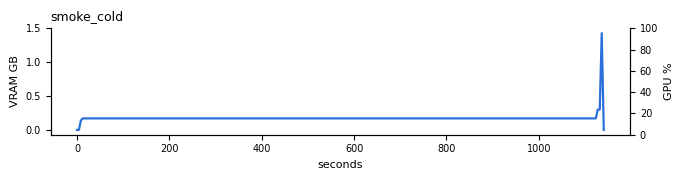

smoke_cold failed (bindless_rt, assert); retrying with: bindless for all shader types
▶ smoke_cold (attempt 2: bindless for all shader types)
  │ 0:00 Failed to find game directory: /content/x3due/engine/X3DLab/Binaries
  │ 0:00 LogInit: Display: Running engine for game: X3DLab
  │ 0:00 LogCore: Display: Requested channels: 'cpu,gpu,frame,log,bookmark,screenshot,region'
  │ 0:00 LogCsvProfiler: Display: Metadata set : commandline="" /content/x3due/X3DLab/X3DLab.uproject /Engine/Maps/Entry -game -RenderOffscreen -vulkan -windowed -ResX=640 -ResY=360 -log -ExecCmds=quit -sm6 -…
  │ 0:01 LogConfig: No local boot hotfix file found at: [../../../../X3DLab/Saved/PersistentDownloadDir/HotfixForNextBoot.txt]
  │ 0:03 LogInit: Build: ++UE5+Release-5.4-CL-35576357
  │ 0:03 LogInit: Engine Version: 5.4.4-35576357+++UE5+Release-5.4
  │ 0:03 LogCoreRedirects: AddRedirect(/content/x3due/X3DLab/Saved/Config/LinuxEditor/MDLImporter.ini) has substring redirect /DatasmithContent/Materials/MDL/, these ar

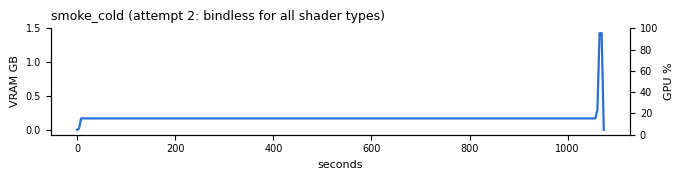

cold start: rc 0 in 1076 s · PASS · Vulkan RHI on NVIDIA L4
▶ smoke_warm
  │ 0:00 Failed to find game directory: /content/x3due/engine/X3DLab/Binaries
  │ 0:00 LogInit: Display: Running engine for game: X3DLab
  │ 0:00 LogCore: Display: Requested channels: 'cpu,gpu,frame,log,bookmark,screenshot,region'
  │ 0:00 LogCsvProfiler: Display: Metadata set : commandline="" /content/x3due/X3DLab/X3DLab.uproject /Engine/Maps/Entry -game -RenderOffscreen -vulkan -windowed -ResX=640 -ResY=360 -log -ExecCmds=quit -sm6 -…
  │ 0:01 LogConfig: No local boot hotfix file found at: [../../../../X3DLab/Saved/PersistentDownloadDir/HotfixForNextBoot.txt]
  │ 0:02 LogInit: Build: ++UE5+Release-5.4-CL-35576357
  │ 0:02 LogInit: Engine Version: 5.4.4-35576357+++UE5+Release-5.4
  │ 0:02 LogCoreRedirects: AddRedirect(/content/x3due/X3DLab/Saved/Config/LinuxEditor/MDLImporter.ini) has substring redirect /DatasmithContent/Materials/MDL/, these are very slow and should be resolved as so…
  │ 0:03 LogConfig: Applyin

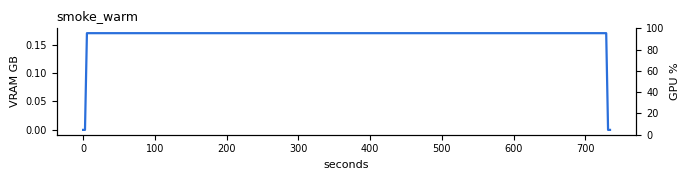

warm start: rc 143 in 736 s · PASS · Vulkan RHI on NVIDIA L4
cold start: retried with bindless for all shader types
shader cache saved to Drive: {'archive': '/content/drive/MyDrive/x3dlab/unreal/cache/ddc.tar.zst', 'gb': 0.0}


In [14]:
#@title 6 · Cold and warm start { display-mode: "form" }
if CACHE_DDC and Path(DRIVE_DIR).exists():
    CARD["ddc_restore"] = pipeline.ddc_restore(LAB, DRIVE_DIR)
    print("DDC:", CARD["ddc_restore"])
LAB.settings["usd"] = USD == "auto"          # step 8 imports .usdc files: the USD Importer plugin must be on
PROJ = LAB.write_project()
print("project %s · plugins %s · %d shader workers" % (PROJ["project"], ", ".join(p["Name"] for p in PROJ["plugins"] if p["Enabled"]), PROJ["workers"]))
if PROJ["missing_required"] and ENGINE.get("version"):
    SC.add("6 start", "required plugins in this engine", "FAIL", "missing: %s" % PROJ["missing_required"])
SMOKE = {}
if ENGINE.get("version"):
    for label in ("cold", "warm"):
        SMOKE[label] = pipeline.smoke(LAB, "smoke_" + label)
        p = SMOKE[label]["proof"]
        print("%s start: rc %s in %.0f s · %s · %s" % (label, SMOKE[label]["rc"], SMOKE[label]["seconds"], p.get("verdict"), p.get("why")))
    p = SMOKE["cold"]["proof"]
    SC.add("6 start", "RHI is Vulkan on the NVIDIA GPU", p["verdict"], "%s · device %s · vendor %s · %s · driver %s" % (
        p.get("why"), p.get("device"), p.get("vendor_id"), p.get("shader_platform"), p.get("driver")))
    SC.add("6 start", "one-time shader compile (cold start)", "PASS" if SMOKE["cold"]["rc"] == 0 else "WARN",
           "%.0f s cold, %.0f s warm (difference ≈ global shader compile + DDC fill)" % (SMOKE["cold"]["seconds"], SMOKE["warm"]["seconds"]))
    if p["verdict"] != "PASS":
        print("\n--- the log lines that matter ---\n" + SMOKE["cold"]["excerpt"])
        stack = pipeline.crash_stack(LAB)
        if stack:
            print("\n--- Unreal's crash call stack (newest crash) ---\n" + stack)
            CARD.setdefault("crashes", []).append(stack[:1500])
    for k, v in SMOKE.items():
        for a in v.get("attempts") or []:
            if a.get("change"):
                print("%s start: retried with %s" % (k, a["change"]))
    CARD["smoke"] = {k: {x: v.get(x) for x in ("rc", "seconds", "killed", "proof", "gpu", "attempts", "timing")} for k, v in SMOKE.items()}
    if CACHE_DDC and Path(DRIVE_DIR).exists() and SMOKE["cold"]["rc"] == 0 and SMOKE["cold"]["seconds"] > 120:
        # The global shaders are the expensive part (17 min on an A100, hours on a small runtime): keep them now,
        # not only at step 11, so a run that stops later still leaves a warm cache for the next one.
        CARD["ddc_save_after_start"] = pipeline.ddc_save(LAB, DRIVE_DIR)
        print("shader cache saved to Drive:", CARD["ddc_save_after_start"])
else:
    SC.add("6 start", "RHI is Vulkan on the NVIDIA GPU", "SKIP", "no engine (step 5)")

In [15]:
#@title 6b · The REAL shader cache: SAVE after step 6 · RESTORE before step 6 on a new runtime { display-mode: "form" }
# UE 5.4 keeps compiled shaders in its Zen cache under the ue user's home, not in /content/x3due/ddc (that archive was
# 106 bytes = empty). This saves everything Unreal caches: /home/ue, the DDC folder and the project's DerivedDataCache.
MODE = "save"  #@param ["save", "restore", "sizes"]
VERSION = "5.4.4"  #@param {type:"string"}
import os, shutil, subprocess, time
from pathlib import Path
DRIVE = Path(globals().get("DRIVE_DIR", "/content/drive/MyDrive/x3dlab/unreal"))
ARC = DRIVE / "cache" / ("shaders_%s.tar.zst" % VERSION)
PATHS = ["home/ue", "content/x3due/ddc", "content/x3due/X3DLab/DerivedDataCache"]       # relative to /
def sh(c):
    r = subprocess.run(c, shell=True, capture_output=True, text=True)
    return (r.stdout + r.stderr).strip()
if not shutil.which("zstd"):
    sh("apt-get install -y -qq zstd || (apt-get update -qq && apt-get install -y -qq zstd)")
print(sh("du -sh " + " ".join("/" + p for p in PATHS if os.path.exists("/" + p)) + " 2>/dev/null"))
if MODE == "save":
    sh("pkill -u ue -f zenserver; pkill -u ue -f UnrealTraceServer; sleep 3")      # flush and close the cache files
    have = [p for p in PATHS if os.path.exists("/" + p)]
    ARC.parent.mkdir(parents=True, exist_ok=True)
    tmp = Path("/content") / ARC.name
    t0 = time.time()
    out = sh("tar -C / -cf - %s | zstd -T0 -3 -q -f -o %s" % (" ".join(have), tmp))
    gb = tmp.stat().st_size / 2**30
    assert gb > 0.01, "the archive is nearly empty (%.3f GB): did step 6's cold start finish? %s" % (gb, out)
    shutil.copyfile(tmp, str(ARC) + ".part"); os.replace(str(ARC) + ".part", ARC); tmp.unlink()
    print("✅ shader cache saved: %.2f GB in %.0f s → %s" % (gb, time.time() - t0, ARC))
elif MODE == "restore":
    assert ARC.exists(), "no %s yet: run MODE = save after a cold start first" % ARC
    sh("id ue || useradd -m ue")
    t0 = time.time()
    out = sh("zstd -d -c -q %s | tar -C / -xf -" % ARC)
    sh("chown -R ue:ue /home/ue /content/x3due/ddc 2>/dev/null; chown -R ue:ue /content/x3due/X3DLab 2>/dev/null")
    print("✅ restored %.2f GB in %.0f s %s; now run step 6 (the cold start should be much shorter)" % (
        ARC.stat().st_size / 2**30, time.time() - t0, out))

547M	/home/ue
4.0K	/content/x3due/ddc
8.0K	/content/x3due/X3DLab/DerivedDataCache
✅ shader cache saved: 0.21 GB in 1 s → /content/drive/MyDrive/x3dlab/unreal/cache/shaders_5.4.4.tar.zst


## 7 · Scenes in, X3D → glTF (the Foundry's leg)

Each scene is downloaded from its home (pinned commits; licences in the table). X3D scenes go to glTF through the lab's own Blender leg: `x3d-blender-io` import, Blender's glTF export, the **Khronos glTF validator**, and `x3dlab.formats.losses` (what glTF has no place for). *The `-gltf` scenes are controls*: Khronos samples that go straight into Unreal with no Blender step, so Unreal can be judged on the same file X_ITE draws.

**Expected before Unreal** (found by notebook 06 Foundry with minimal repros; they cap the fidelity of whatever reaches Unreal): x3d-blender-io skips IndexedQuadSet and Arc2D · Sphere and Cylinder import flat-shaded · TwoSidedMaterial is dropped · strips and fans become plain faces, point sets are dropped. GLSL `ComposedShader`s (the Gobbler's whole look) cannot travel in glTF at all; DESIGN.md says what can be done about them.

In [16]:
#@title 7 · Download, read, convert { display-mode: "form" }
from x3dlab import blender as xblender, formats
names = [s.strip() for s in SCENES.split(",") if s.strip() in showcase.CATALOGUE]
display(HTML("<div style='font-size:12px'>%s</div>" % showcase.licence_table(names).replace("\n", "<br>")))
BL = None
try:
    BL = xblender.setup()
    print("Blender %s for the X3D → glTF leg" % BL.version)
except Exception as exc:
    print("⚠️ Blender unavailable: %s (X3D scenes are skipped; glTF controls still run)" % exc)
SCN = {}
for n in names:
    e = showcase.CATALOGUE[n]
    rec = {"name": n, "kind": e["kind"]}
    try:
        f = showcase.fetch(n, WORK / "scenes")
        rec.update(fetch=f)
        main = Path(f["main"])
        if e["kind"] == "x3d":
            xml, vp_names = x3dscene.ensure_viewpoint_defs(main.read_text(encoding="utf-8", errors="replace"))
            xml, rec["freeze"] = staging.freeze(xml, e.get("freeze_at", "auto"))       # dark at time 0? freeze it lit
            m0 = x3dscene.manifest(xml)
            rec["framing"] = staging.frame_all(m0)
            if staging.needs_auto(rec["framing"]) and m0.get("bounds"):                 # no authored viewpoint shows it
                xml, _ = staging.add_auto_viewpoint(xml, m0["bounds"])
                rec["framing"] = staging.frame_all(x3dscene.manifest(xml))
            main.write_text(xml, encoding="utf-8")
            rec["manifest"] = x3dscene.manifest(xml)
            if rec["freeze"].get("fraction") is not None:
                print("%s: %s (lights %.3g -> %.3g)" % (n, rec["freeze"]["why"], rec["freeze"]["lights_t0"], rec["freeze"]["lights_frozen"]))
            bad = {k: v["verdict"] for k, v in rec["framing"].items() if v["verdict"] not in ("frames", "inside")}
            if bad:
                print("%s: viewpoints that don't show the model: %s%s" % (n, bad, " · added x3dlab_auto" if "x3dlab_auto" in rec["framing"] else ""))
            if BL is not None:
                conv = engines.to_gltf(BL, main, main.with_suffix(".glb"))
                rec["convert"] = {k: conv.get(k) for k in ("error", "counts", "shared_meshes", "flat_meshes", "losses", "export_s", "bytes")}
                rec["validator"] = {k: (conv.get("validator") or {}).get(k) for k in ("ok", "errors", "warnings")}
                rec["glb"] = conv.get("output") if not conv.get("error") else None
                if USD == "auto" and not conv.get("error"):
                    u = engines.to_gltf(BL, main, main.with_suffix(".usdc"), fmt="usd")
                    rec["usd"] = u.get("output") if not u.get("error") else None
                    rec["usd_error"] = u.get("error")
        else:
            rec["glb"] = str(main)
            gs = gltfstat.stats(main)
            cs = gs["shape_centres"]
            lo = tuple(min(c[i] for c in cs) for i in range(3)) if cs else (-1, -1, -1)
            hi = tuple(max(c[i] for c in cs) for i in range(3)) if cs else (1, 1, 1)
            xml, vp = compare.gltf_control_x3d(main.name, (lo, hi))
            (main.parent / "control.x3d").write_text(xml, encoding="utf-8")
            m = x3dscene.manifest(xml)
            m["bounds"], m["shape_centres"] = (lo, hi), cs
            rec["manifest"], rec["wrapper"] = m, str(main.parent / "control.x3d")
        if rec.get("glb"):
            rec["gltf"] = gltfstat.stats(rec["glb"])
        c = rec["manifest"]["counts"]
        lo_ = (rec.get("convert") or {}).get("losses") or {}
        print("%-14s %5d nodes · %d shapes · %d viewpoints · %d lights · glTF %s%s" % (
            n, c["nodes"], c["shape_instances"], c["viewpoints"], c["lights"], "✓" if rec.get("glb") else "✗",
            ("  · expected losses: %s · unexpected: %s" % (", ".join(lo_.get("expected", [])[:6]) or "none", "; ".join(lo_.get("unexpected", [])) or "none")) if lo_ else ""))
        if rec.get("validator", {}).get("ok") is False:
            SC.add("7 scenes", "%s: glTF valid (Khronos)" % n, "WARN", "%s errors" % rec["validator"].get("errors"))
        SC.add("7 scenes", "%s: in and converted" % n, "PASS" if rec.get("glb") else "FAIL",
               "%d viewpoints, %s missing files%s" % (c["viewpoints"], len(f.get("missing", [])), "; " + (rec.get("convert") or {}).get("error", "") if (rec.get("convert") or {}).get("error") else ""))
    except Exception as exc:
        rec["error"] = str(exc)
        SC.add("7 scenes", "%s: in and converted" % n, "FAIL", str(exc)[:300])
    SCN[n] = rec
CARD["scenes"] = {n: {k: v for k, v in r.items() if k not in ("manifest",)} | {"counts": (r.get("manifest") or {}).get("counts"),
                  "traps": (r.get("manifest") or {}).get("traps")} for n, r in SCN.items()}

18:57:17 INFO  install   git clone hagopjay/x3d-blender-io (2396 ms)
18:57:17 INFO  install   hagopjay/x3d-blender-io at d9bbf91
18:57:40 INFO  install   pip install bpy==5.2.3 (about 400 MB) (22160 ms)
18:57:42 INFO  blender   probe probe ok (0.2 s)
18:57:42 INFO  blender   Blender 5.2.3 LTS · best Cycles backend: OPTIX
Blender 5.2.3 LTS for the X3D → glTF leg
18:57:43 WARN  blender   ERROR Draco is not available because library could not be found at /usr/local/lib/python3.13/dist-packages/bpy/lib/libbf_intern_draco_bridge.so
18:57:43 WARN  blender   ERROR MeshOptimizer is not available because library could not be found at /usr/local/lib/python3.13/dist-packages/bpy/lib/libbf_intern_meshopt_bridge.so
18:57:43 INFO  blender   unreal-convert convert ok (0.3 s)
18:57:44 INFO  formats   npm install gltf-validator@2.0.0-dev.3.10 (898 ms)
18:57:45 INFO  blender   unreal-convert convert ok (0.2 s)
calib             12 nodes · 1 shapes · 1 viewpoints · 1 lights · glTF ✓  · expected losses: B

## 8 · Into Unreal: import, account, calibrate

One editor task per scene (a fresh process: no state leaks from one scene to the next): Interchange imports the glTF into a new level; the script measures what arrived, works out which axis mapping the importer used (from the shapes' centres, not by assumption), places the X3D viewpoints as cameras and the X3D lights in physical units, adds the backdrop (the X3D Background colour) and makes one sequence per viewpoint. Then the accounting: **glTF in vs Unreal out**, row by row.

**Calibration first.** X3D light intensity has no unit; Unreal's are lux and candela, and the picture depends on exposure. The `calib` scene (one white box, one light of intensity 1, head-on) is rendered with no tone curve; its brightness gives the constant every later scene's lights are converted with. **Field of view:** X3D's applies to the *shorter* image side, Unreal's is horizontal; cameras get a filmback with the image's aspect and the matching focal length.

▶ import_calib
  │ 0:00 Failed to find game directory: /content/x3due/engine/X3DLab/Binaries
  │ 0:00 LogInit: Display: Running engine for game: X3DLab
  │ 0:00 LogCore: Display: Requested channels: 'cpu,gpu,frame,log,bookmark,screenshot,region'
  │ 0:00 LogCsvProfiler: Display: Metadata set : commandline="" /content/x3due/X3DLab/X3DLab.uproject -run=pythonscript -script=/content/x3due/X3DLab/Content/Python/x3dlab_import.py -unattended -nosplash -nos…
  │ 0:01 LogConfig: No local boot hotfix file found at: [../../../../X3DLab/Saved/PersistentDownloadDir/HotfixForNextBoot.txt]
  │ 0:02 LogInit: Build: ++UE5+Release-5.4-CL-35576357
  │ 0:02 LogInit: Engine Version: 5.4.4-35576357+++UE5+Release-5.4
  │ 0:02 LogInit: Command Line:  /content/x3due/X3DLab/X3DLab.uproject -run=pythonscript -script=/content/x3due/X3DLab/Content/Python/x3dlab_import.py -unattended -nosplash -nosound -nopause -stdout -FullStdO…
  │ 0:02 LogCoreRedirects: AddRedirect(/content/x3due/X3DLab/Saved/Config/LinuxEditor

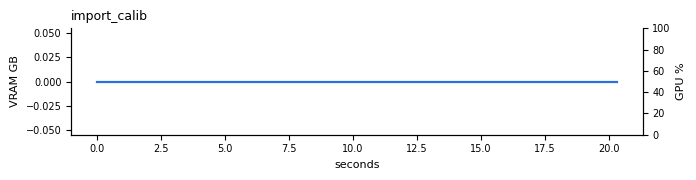

▶ import_calib_usd
  │ 0:00 Failed to find game directory: /content/x3due/engine/X3DLab/Binaries
  │ 0:00 LogInit: Display: Running engine for game: X3DLab
  │ 0:00 LogCore: Display: Requested channels: 'cpu,gpu,frame,log,bookmark,screenshot,region'
  │ 0:00 LogCsvProfiler: Display: Metadata set : commandline="" /content/x3due/X3DLab/X3DLab.uproject -run=pythonscript -script=/content/x3due/X3DLab/Content/Python/x3dlab_import.py -unattended -nosplash -nos…
  │ 0:01 LogConfig: No local boot hotfix file found at: [../../../../X3DLab/Saved/PersistentDownloadDir/HotfixForNextBoot.txt]
  │ 0:02 LogInit: Build: ++UE5+Release-5.4-CL-35576357
  │ 0:02 LogInit: Engine Version: 5.4.4-35576357+++UE5+Release-5.4
  │ 0:02 LogInit: Command Line:  /content/x3due/X3DLab/X3DLab.uproject -run=pythonscript -script=/content/x3due/X3DLab/Content/Python/x3dlab_import.py -unattended -nosplash -nosound -nopause -stdout -FullStdO…
  │ 0:02 LogCoreRedirects: AddRedirect(/content/x3due/X3DLab/Saved/Config/LinuxEd

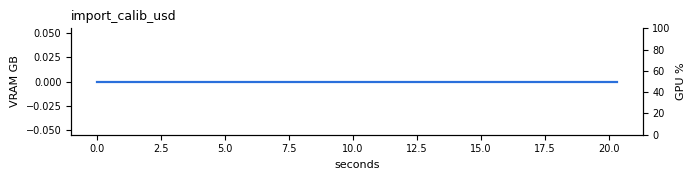

▶ render_calib_preview_match
  │ 0:00 Failed to find game directory: /content/x3due/engine/X3DLab/Binaries
  │ 0:00 LogInit: Display: Running engine for game: X3DLab
  │ 0:00 LogCore: Display: Requested channels: 'cpu,gpu,frame,log,bookmark,screenshot,region'
  │ 0:00 LogCsvProfiler: Display: Metadata set : commandline="" /content/x3due/X3DLab/X3DLab.uproject /Game/X3DLab/calib/Map_calib -game -MoviePipelineLocalExecutorClass=/Script/MovieRenderPipelineCore.MovieP…
  │ 0:01 LogConfig: No local boot hotfix file found at: [../../../../X3DLab/Saved/PersistentDownloadDir/HotfixForNextBoot.txt]
  │ 0:02 LogInit: Build: ++UE5+Release-5.4-CL-35576357
  │ 0:02 LogInit: Engine Version: 5.4.4-35576357+++UE5+Release-5.4
  │ 0:02 LogInit: Command Line: /Game/X3DLab/calib/Map_calib -game -MoviePipelineLocalExecutorClass=/Script/MovieRenderPipelineCore.MoviePipelinePythonHostExecutor -ExecutorPythonClass=/Engine/PythonTypes.X3D…
  │ 0:02 LogCoreRedirects: AddRedirect(/content/x3due/X3DLab/Saved/Conf

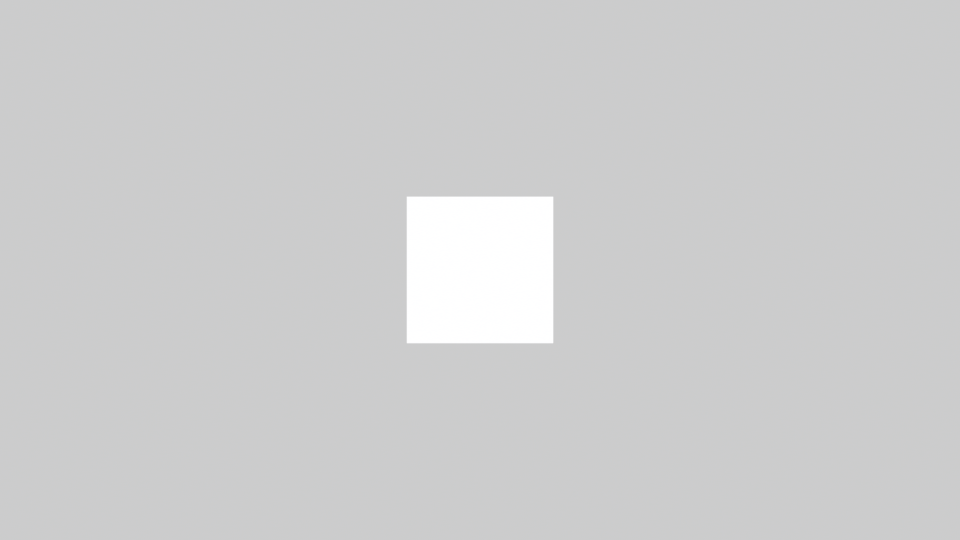

  🖼 render_calib_preview_match · calib__Front__preview.0001.png · 0:59


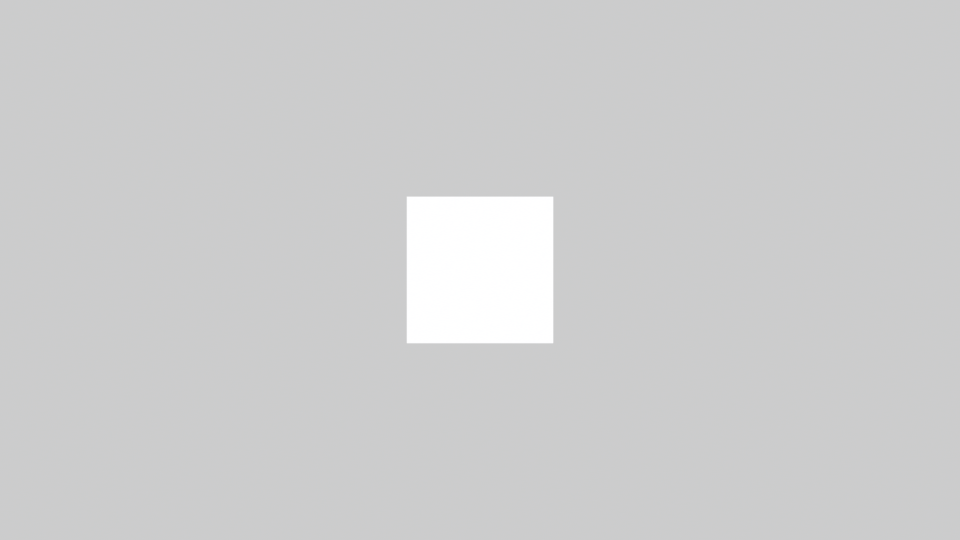

  │ 0:59 LogPython: X3DLAB: wrote calib__Front__preview (4 files, 34.2 s)
  │ 0:59 LogPython: X3DLAB: executor finished
  │ 0:59 LogWorld: BeginTearingDown for /Game/X3DLab/calib/Map_calib
  │ 0:59 LogSlate: Window 'X3DLab (64-bit Development SF_VULKAN_SM6) ' being destroyed
  │ 0:59 LogShaderCompilers: Display: Shaders left to compile 0
  ⏱ 1:00 · shaders: 0 jobs done, 0 left · 0 workers · Unreal 2.4 GB · RAM 3.9/53 GB · VRAM 2.8/22 GB · GPU 0% · disk 177 GB free
  │ 1:00 LogExit: Exiting.
  │ 1:02 CrashReportCoreLog: Display: Applying project settings from '/content/x3due/X3DLab/Saved/Crashes/ensureinfo-X3DLab-pid-35541-1DF50406058441CF95AA22FD999E3DBD/CrashReportClient.ini'.
  │ 1:02 CrashReportCoreLog: Got 4 pending files to upload from 'ensureinfo-X3DLab-pid-35541-1DF50406058441CF95AA22FD999E3DBD'
  │ 1:02 CrashReportCoreLog: CompressAndSendData compressing 179 bytes ('/content/x3due/X3DLab/Saved/Crashes/ensureinfo-X3DLab-pid-35541-1DF50406058441CF95AA22FD999E3DBD/CrashReportClien

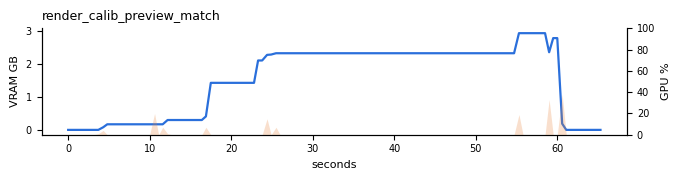

▶ import_stilllife
  │ 0:00 Failed to find game directory: /content/x3due/engine/X3DLab/Binaries
  │ 0:00 LogInit: Display: Running engine for game: X3DLab
  │ 0:00 LogCore: Display: Requested channels: 'cpu,gpu,frame,log,bookmark,screenshot,region'
  │ 0:00 LogCsvProfiler: Display: Metadata set : commandline="" /content/x3due/X3DLab/X3DLab.uproject -run=pythonscript -script=/content/x3due/X3DLab/Content/Python/x3dlab_import.py -unattended -nosplash -nos…
  │ 0:01 LogConfig: No local boot hotfix file found at: [../../../../X3DLab/Saved/PersistentDownloadDir/HotfixForNextBoot.txt]
  │ 0:02 LogInit: Build: ++UE5+Release-5.4-CL-35576357
  │ 0:02 LogInit: Engine Version: 5.4.4-35576357+++UE5+Release-5.4
  │ 0:02 LogInit: Command Line:  /content/x3due/X3DLab/X3DLab.uproject -run=pythonscript -script=/content/x3due/X3DLab/Content/Python/x3dlab_import.py -unattended -nosplash -nosound -nopause -stdout -FullStdO…
  │ 0:02 LogCoreRedirects: AddRedirect(/content/x3due/X3DLab/Saved/Config/LinuxEd

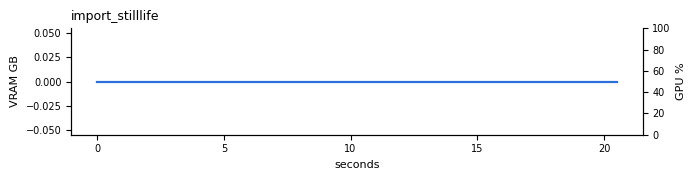

▶ import_stilllife_usd
  │ 0:00 Failed to find game directory: /content/x3due/engine/X3DLab/Binaries
  │ 0:00 LogInit: Display: Running engine for game: X3DLab
  │ 0:00 LogCore: Display: Requested channels: 'cpu,gpu,frame,log,bookmark,screenshot,region'
  │ 0:00 LogCsvProfiler: Display: Metadata set : commandline="" /content/x3due/X3DLab/X3DLab.uproject -run=pythonscript -script=/content/x3due/X3DLab/Content/Python/x3dlab_import.py -unattended -nosplash -nos…
  │ 0:01 LogConfig: No local boot hotfix file found at: [../../../../X3DLab/Saved/PersistentDownloadDir/HotfixForNextBoot.txt]
  │ 0:02 LogInit: Build: ++UE5+Release-5.4-CL-35576357
  │ 0:02 LogInit: Engine Version: 5.4.4-35576357+++UE5+Release-5.4
  │ 0:02 LogInit: Command Line:  /content/x3due/X3DLab/X3DLab.uproject -run=pythonscript -script=/content/x3due/X3DLab/Content/Python/x3dlab_import.py -unattended -nosplash -nosound -nopause -stdout -FullStdO…
  │ 0:02 LogCoreRedirects: AddRedirect(/content/x3due/X3DLab/Saved/Config/Lin

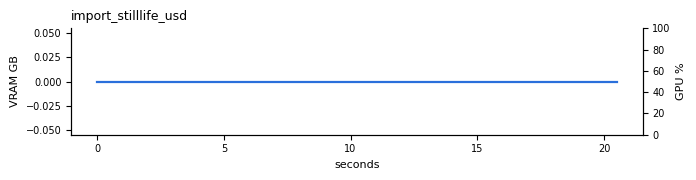

stilllife      mesh 5→5 · meshes 5→5 · shared 0→0 · triangles 27560→27560 · materials 5→5 · textures 1→1
▶ import_toycar_x3d
  │ 0:00 Failed to find game directory: /content/x3due/engine/X3DLab/Binaries
  │ 0:00 LogInit: Display: Running engine for game: X3DLab
  │ 0:00 LogCore: Display: Requested channels: 'cpu,gpu,frame,log,bookmark,screenshot,region'
  │ 0:00 LogCsvProfiler: Display: Metadata set : commandline="" /content/x3due/X3DLab/X3DLab.uproject -run=pythonscript -script=/content/x3due/X3DLab/Content/Python/x3dlab_import.py -unattended -nosplash -nos…
  │ 0:01 LogConfig: No local boot hotfix file found at: [../../../../X3DLab/Saved/PersistentDownloadDir/HotfixForNextBoot.txt]
  │ 0:02 LogInit: Build: ++UE5+Release-5.4-CL-35576357
  │ 0:02 LogInit: Engine Version: 5.4.4-35576357+++UE5+Release-5.4
  │ 0:02 LogInit: Command Line:  /content/x3due/X3DLab/X3DLab.uproject -run=pythonscript -script=/content/x3due/X3DLab/Content/Python/x3dlab_import.py -unattended -nosplash -nosound -no

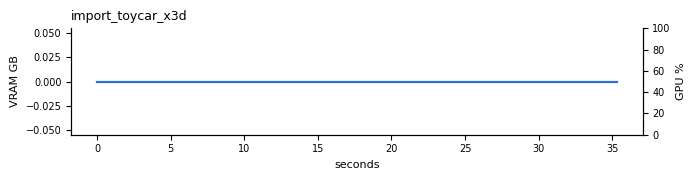

▶ import_toycar_x3d_usd
  │ 0:00 Failed to find game directory: /content/x3due/engine/X3DLab/Binaries
  │ 0:00 LogInit: Display: Running engine for game: X3DLab
  │ 0:00 LogCore: Display: Requested channels: 'cpu,gpu,frame,log,bookmark,screenshot,region'
  │ 0:00 LogCsvProfiler: Display: Metadata set : commandline="" /content/x3due/X3DLab/X3DLab.uproject -run=pythonscript -script=/content/x3due/X3DLab/Content/Python/x3dlab_import.py -unattended -nosplash -nos…
  │ 0:01 LogConfig: No local boot hotfix file found at: [../../../../X3DLab/Saved/PersistentDownloadDir/HotfixForNextBoot.txt]
  │ 0:02 LogInit: Build: ++UE5+Release-5.4-CL-35576357
  │ 0:02 LogInit: Engine Version: 5.4.4-35576357+++UE5+Release-5.4
  │ 0:02 LogInit: Command Line:  /content/x3due/X3DLab/X3DLab.uproject -run=pythonscript -script=/content/x3due/X3DLab/Content/Python/x3dlab_import.py -unattended -nosplash -nosound -nopause -stdout -FullStdO…
  │ 0:02 LogCoreRedirects: AddRedirect(/content/x3due/X3DLab/Saved/Config/Li

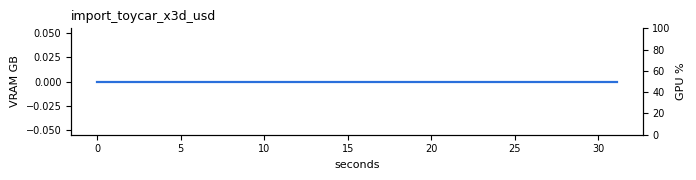

toycar-x3d     mesh 3→3 · meshes 3→3 · shared 0→0 · triangles 108936→108936 · materials 3→3 · textures 6→6
▶ import_toycar_gltf
  │ 0:00 Failed to find game directory: /content/x3due/engine/X3DLab/Binaries
  │ 0:00 LogInit: Display: Running engine for game: X3DLab
  │ 0:00 LogCore: Display: Requested channels: 'cpu,gpu,frame,log,bookmark,screenshot,region'
  │ 0:00 LogCsvProfiler: Display: Metadata set : commandline="" /content/x3due/X3DLab/X3DLab.uproject -run=pythonscript -script=/content/x3due/X3DLab/Content/Python/x3dlab_import.py -unattended -nosplash -nos…
  │ 0:01 LogConfig: No local boot hotfix file found at: [../../../../X3DLab/Saved/PersistentDownloadDir/HotfixForNextBoot.txt]
  │ 0:02 LogInit: Build: ++UE5+Release-5.4-CL-35576357
  │ 0:02 LogInit: Engine Version: 5.4.4-35576357+++UE5+Release-5.4
  │ 0:02 LogInit: Command Line:  /content/x3due/X3DLab/X3DLab.uproject -run=pythonscript -script=/content/x3due/X3DLab/Content/Python/x3dlab_import.py -unattended -nosplash -nosound 

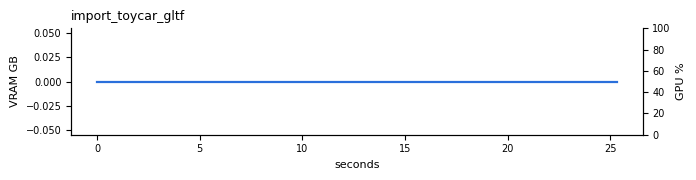

toycar-gltf    mesh 3→3 · meshes 3→3 · shared 0→0 · triangles 108936→108936 · materials 3→3 · textures 8→8
▶ import_odyssey
  │ 0:00 Failed to find game directory: /content/x3due/engine/X3DLab/Binaries
  │ 0:00 LogInit: Display: Running engine for game: X3DLab
  │ 0:00 LogCore: Display: Requested channels: 'cpu,gpu,frame,log,bookmark,screenshot,region'
  │ 0:00 LogCsvProfiler: Display: Metadata set : commandline="" /content/x3due/X3DLab/X3DLab.uproject -run=pythonscript -script=/content/x3due/X3DLab/Content/Python/x3dlab_import.py -unattended -nosplash -nos…
  │ 0:01 LogConfig: No local boot hotfix file found at: [../../../../X3DLab/Saved/PersistentDownloadDir/HotfixForNextBoot.txt]
  │ 0:02 LogInit: Build: ++UE5+Release-5.4-CL-35576357
  │ 0:02 LogInit: Engine Version: 5.4.4-35576357+++UE5+Release-5.4
  │ 0:02 LogInit: Command Line:  /content/x3due/X3DLab/X3DLab.uproject -run=pythonscript -script=/content/x3due/X3DLab/Content/Python/x3dlab_import.py -unattended -nosplash -nosound -nop

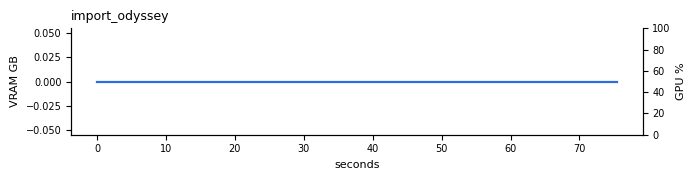

▶ import_odyssey_usd
  │ 0:00 Failed to find game directory: /content/x3due/engine/X3DLab/Binaries
  │ 0:00 LogInit: Display: Running engine for game: X3DLab
  │ 0:00 LogCore: Display: Requested channels: 'cpu,gpu,frame,log,bookmark,screenshot,region'
  │ 0:00 LogCsvProfiler: Display: Metadata set : commandline="" /content/x3due/X3DLab/X3DLab.uproject -run=pythonscript -script=/content/x3due/X3DLab/Content/Python/x3dlab_import.py -unattended -nosplash -nos…
  │ 0:01 LogConfig: No local boot hotfix file found at: [../../../../X3DLab/Saved/PersistentDownloadDir/HotfixForNextBoot.txt]
  │ 0:02 LogInit: Build: ++UE5+Release-5.4-CL-35576357
  │ 0:02 LogInit: Engine Version: 5.4.4-35576357+++UE5+Release-5.4
  │ 0:02 LogInit: Command Line:  /content/x3due/X3DLab/X3DLab.uproject -run=pythonscript -script=/content/x3due/X3DLab/Content/Python/x3dlab_import.py -unattended -nosplash -nosound -nopause -stdout -FullStdO…
  │ 0:02 LogCoreRedirects: AddRedirect(/content/x3due/X3DLab/Saved/Config/Linux

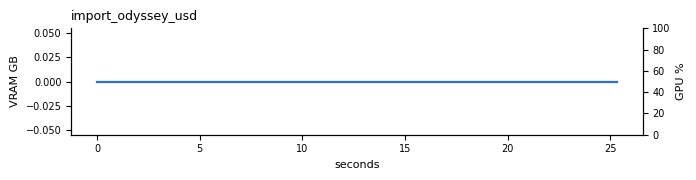

odyssey        mesh 285→285 · meshes 273→273 · shared 12→12 · triangles 82610→82610 · materials 100→100 · textures 170→170
▶ import_gobbler3
  │ 0:00 Failed to find game directory: /content/x3due/engine/X3DLab/Binaries
  │ 0:00 LogInit: Display: Running engine for game: X3DLab
  │ 0:00 LogCore: Display: Requested channels: 'cpu,gpu,frame,log,bookmark,screenshot,region'
  │ 0:00 LogCsvProfiler: Display: Metadata set : commandline="" /content/x3due/X3DLab/X3DLab.uproject -run=pythonscript -script=/content/x3due/X3DLab/Content/Python/x3dlab_import.py -unattended -nosplash -nos…
  │ 0:01 LogConfig: No local boot hotfix file found at: [../../../../X3DLab/Saved/PersistentDownloadDir/HotfixForNextBoot.txt]
  │ 0:02 LogInit: Build: ++UE5+Release-5.4-CL-35576357
  │ 0:02 LogInit: Engine Version: 5.4.4-35576357+++UE5+Release-5.4
  │ 0:02 LogInit: Command Line:  /content/x3due/X3DLab/X3DLab.uproject -run=pythonscript -script=/content/x3due/X3DLab/Content/Python/x3dlab_import.py -unattended -nospl

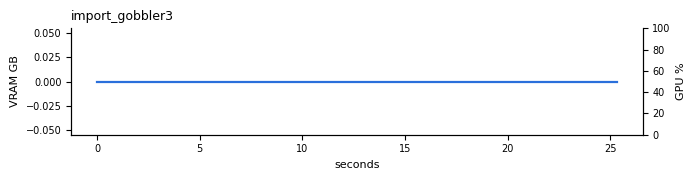

▶ import_gobbler3_usd
  │ 0:00 Failed to find game directory: /content/x3due/engine/X3DLab/Binaries
  │ 0:00 LogInit: Display: Running engine for game: X3DLab
  │ 0:00 LogCore: Display: Requested channels: 'cpu,gpu,frame,log,bookmark,screenshot,region'
  │ 0:00 LogCsvProfiler: Display: Metadata set : commandline="" /content/x3due/X3DLab/X3DLab.uproject -run=pythonscript -script=/content/x3due/X3DLab/Content/Python/x3dlab_import.py -unattended -nosplash -nos…
  │ 0:01 LogConfig: No local boot hotfix file found at: [../../../../X3DLab/Saved/PersistentDownloadDir/HotfixForNextBoot.txt]
  │ 0:02 LogInit: Build: ++UE5+Release-5.4-CL-35576357
  │ 0:02 LogInit: Engine Version: 5.4.4-35576357+++UE5+Release-5.4
  │ 0:02 LogInit: Command Line:  /content/x3due/X3DLab/X3DLab.uproject -run=pythonscript -script=/content/x3due/X3DLab/Content/Python/x3dlab_import.py -unattended -nosplash -nosound -nopause -stdout -FullStdO…
  │ 0:02 LogCoreRedirects: AddRedirect(/content/x3due/X3DLab/Saved/Config/Linu

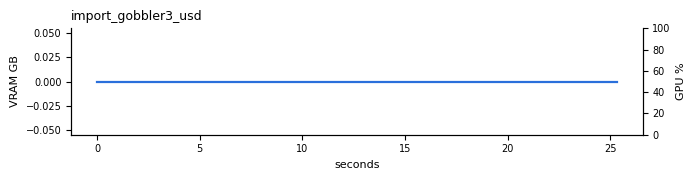

gobbler3       mesh 7→7 · meshes 7→7 · shared 0→0 · triangles 2297→2297 · materials 7→7 · textures 0→None


In [17]:
#@title 8 · Import every scene, calibrate the lights { display-mode: "form" }
IMP = {}
def do_import(n):
    r = SCN[n]
    res = pipeline.import_scene(LAB, n, r["glb"], "gltf", r["manifest"], shape_centres=r["manifest"].get("shape_centres"))
    rep = res["report"]
    IMP[n] = res
    rows = report.account(r["gltf"], rep, r["manifest"], rep)
    st = "PASS" if rep.get("ok") else "FAIL"
    SC.add("8 import", "%s: Interchange import" % n, st, "%s · %d sequences · %.0f s%s" % (
        "ok" if rep.get("ok") else "; ".join(rep.get("errors", [])[:2]) or "failed", len(rep.get("sequences", {})), res["seconds"],
        " · %d API names differ in this engine" % len(rep.get("api_misses", [])) if rep.get("api_misses") else ""))
    for row in rows:
        SC.add("8 import", "%s: %s" % (n, row["what"]), row["status"], row["reason"])
    if not rep.get("ok"):
        print("--- %s: the log lines that matter ---\n%s" % (n, res["excerpt"][-3000:]))
    if r.get("usd"):
        u = pipeline.import_scene(LAB, n, r["usd"], "usd", r["manifest"], shape_centres=r["manifest"].get("shape_centres"))
        IMP[n + "_usd"] = u
        SC.add("8 import", "%s: USD import (second path)" % n, "PASS" if u["report"].get("ok") else "WARN",
               "%s via %s" % ("ok" if u["report"].get("ok") else "; ".join(u["report"].get("errors", [])[:2]) or "failed", u["report"].get("usd_path")))
    return rows

CALIB = None
if ENGINE.get("version") and "calib" in SCN and SCN["calib"].get("glb"):
    do_import("calib")
    cams = sorted((IMP["calib"]["report"].get("sequences") or {}))
    rc = pipeline.render(LAB, "calib", cams, "preview", PLAN["ladder"]["preview"], look="match", res_override=(960, 540))
    png = next((s["png"] for s in rc["stills"] if s["png"]), None)
    if png:
        CALIB = pipeline.calibration(png, LAB.mapping.k)
        if CALIB["use"]:
            LAB.mapping = convert.LightMapping(measured_k=CALIB["k_measured"])
        SC.add("8 import", "light calibration (X3D intensity 1 → Unreal)", "PASS" if CALIB["use"] else "WARN",
               "box centre %.3f linear vs %.3f expected → K %s (assumed %.3f)" % (CALIB["centre_linear"], CALIB["expected_linear"],
                                                                                 CALIB["k_measured"], CALIB["k_assumed"]))
    else:
        SC.add("8 import", "light calibration (X3D intensity 1 → Unreal)", "FAIL", "no calibration still: %s" % rc["proof"].get("why"))
    CARD["calibration"] = {"result": CALIB, "mapping": LAB.mapping.describe()}
for n in SCN:
    if n != "calib" and ENGINE.get("version") and SCN[n].get("glb"):
        rows = do_import(n)
        print("%-14s " % n + " · ".join("%s %s→%s" % (r["what"].split(" ")[0], r["gltf"], r["unreal"]) for r in rows[:6]))
CARD["imports"] = {n: {"report": {k: v for k, v in r["report"].items() if k != "steps"}, "seconds": r["seconds"], "attempts": r["attempts"]}
                   for n, r in IMP.items()}

In [18]:
!ls -la

total 32
drwxr-xr-x 1 root root 4096 Nov 11 18:57 .
drwxr-xr-x 1 root root 4096 Aug 28  2025 ..
drwxr-xr-x 4 root root 4096 Nov  9 16:02 .config
drwx------ 5 root root 4096 Nov 11 17:54 drive
drwxr-xr-x 1 root root 4096 Oct 21 13:28 sample_data
drwxr-xr-x 9 root root 4096 Nov 11 17:51 x3d.lab
drwxr-xr-x 5 root root 4096 Nov 11 18:57 x3dlab
drwxr-xr-x 7 ue   ue   4096 Nov 11 18:57 x3due


In [19]:
#@title 8½ · Stills fix: samples that actually accumulate (shutter angle is 0 → temporal samples collapse) { display-mode: "form" }
for name, r in PLAN["ladder"].items():
    if r["temporal_samples"] > 1:
        r["spatial_samples"], r["temporal_samples"] = r["spatial_samples"] * r["temporal_samples"], 1
    print("%-12s %dx%d %-10s spatial %3d · temporal %d" % (name, *r["resolution"], r["renderer"], r["spatial_samples"], r["temporal_samples"]))

preview      1600x900 lumen      spatial   8 · temporal 1
high         2560x1440 lumen      spatial  32 · temporal 1
ultra        3840x2160 pathtracer spatial 512 · temporal 1
ultra_lumen  3840x2160 lumen      spatial 128 · temporal 1


## 9 · Stills: the ladder

Every viewpoint (up to `MAX_VIEWPOINTS` per scene) through Movie Render Queue at the chosen rung, EXR + PNG. *preview* / *high* use Lumen; *ultra* uses the **path tracer** where the GPU has RT cores (G4, L4, T4) and Lumen at 8K with resident textures where it has the VRAM but no RT cores (A100). VRAM is sampled with `nvidia-smi` during each render; the time per still, the settings, engine version, GPU and driver go into the run card.

rung high: 2560x1440 · lumen · 32 spatial x 1 temporal samples · textures default
▶ render_stilllife_high_cinematic
  │ 0:00 Failed to find game directory: /content/x3due/engine/X3DLab/Binaries
  │ 0:00 LogInit: Display: Running engine for game: X3DLab
  │ 0:00 LogCore: Display: Requested channels: 'cpu,gpu,frame,log,bookmark,screenshot,region'
  │ 0:00 LogCsvProfiler: Display: Metadata set : commandline="" /content/x3due/X3DLab/X3DLab.uproject /Game/X3DLab/stilllife/Map_stilllife -game -MoviePipelineLocalExecutorClass=/Script/MovieRenderPipelineCor…
  │ 0:01 LogConfig: No local boot hotfix file found at: [../../../../X3DLab/Saved/PersistentDownloadDir/HotfixForNextBoot.txt]
  │ 0:02 LogInit: Build: ++UE5+Release-5.4-CL-35576357
  │ 0:02 LogInit: Engine Version: 5.4.4-35576357+++UE5+Release-5.4
  │ 0:02 LogInit: Command Line: /Game/X3DLab/stilllife/Map_stilllife -game -MoviePipelineLocalExecutorClass=/Script/MovieRenderPipelineCore.MoviePipelinePythonHostExecutor -ExecutorPythonClass=/

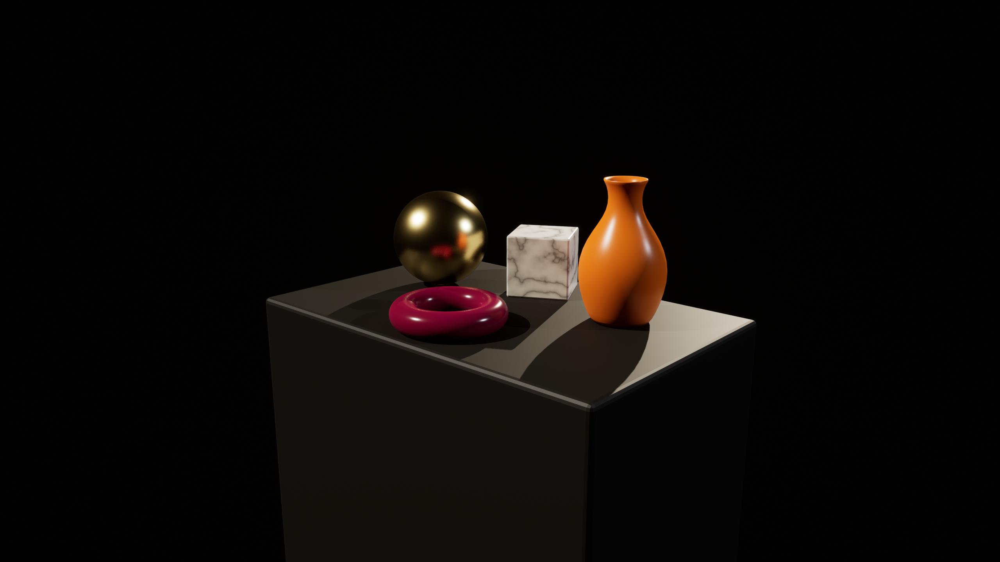

  │ 0:30 LogPython: X3DLAB: wrote stilllife__CA_Camera__high (2 files, 6.7 s)
  │ 0:30 LogPython: X3DLAB: executor finished
  │ 0:30 LogWorld: BeginTearingDown for /Game/X3DLab/stilllife/Map_stilllife
  │ 0:30 LogSlate: Window 'X3DLab (64-bit Development SF_VULKAN_SM6) ' being destroyed
  │ 0:32 LogExit: Exiting.
■ render_stilllife_high_cinematic: rc 0 in 0:35 · peak VRAM 4.3 GB, GPU up to 100%


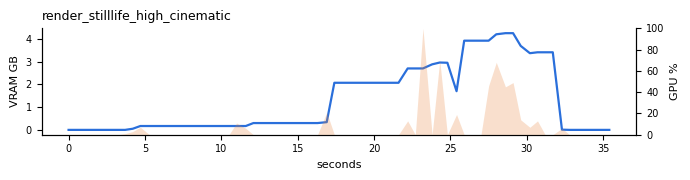

▶ render_toycar_x3d_high_cinematic
  │ 0:00 Failed to find game directory: /content/x3due/engine/X3DLab/Binaries
  │ 0:00 LogInit: Display: Running engine for game: X3DLab
  │ 0:00 LogCore: Display: Requested channels: 'cpu,gpu,frame,log,bookmark,screenshot,region'
  │ 0:00 LogCsvProfiler: Display: Metadata set : commandline="" /content/x3due/X3DLab/X3DLab.uproject /Game/X3DLab/toycar_x3d/Map_toycar_x3d -game -MoviePipelineLocalExecutorClass=/Script/MovieRenderPipelineC…
  │ 0:01 LogConfig: No local boot hotfix file found at: [../../../../X3DLab/Saved/PersistentDownloadDir/HotfixForNextBoot.txt]
  │ 0:02 LogInit: Build: ++UE5+Release-5.4-CL-35576357
  │ 0:02 LogInit: Engine Version: 5.4.4-35576357+++UE5+Release-5.4
  │ 0:02 LogInit: Command Line: /Game/X3DLab/toycar_x3d/Map_toycar_x3d -game -MoviePipelineLocalExecutorClass=/Script/MovieRenderPipelineCore.MoviePipelinePythonHostExecutor -ExecutorPythonClass=/Engine/Pytho…
  │ 0:02 LogCoreRedirects: AddRedirect(/content/x3due/X3DLab/Save

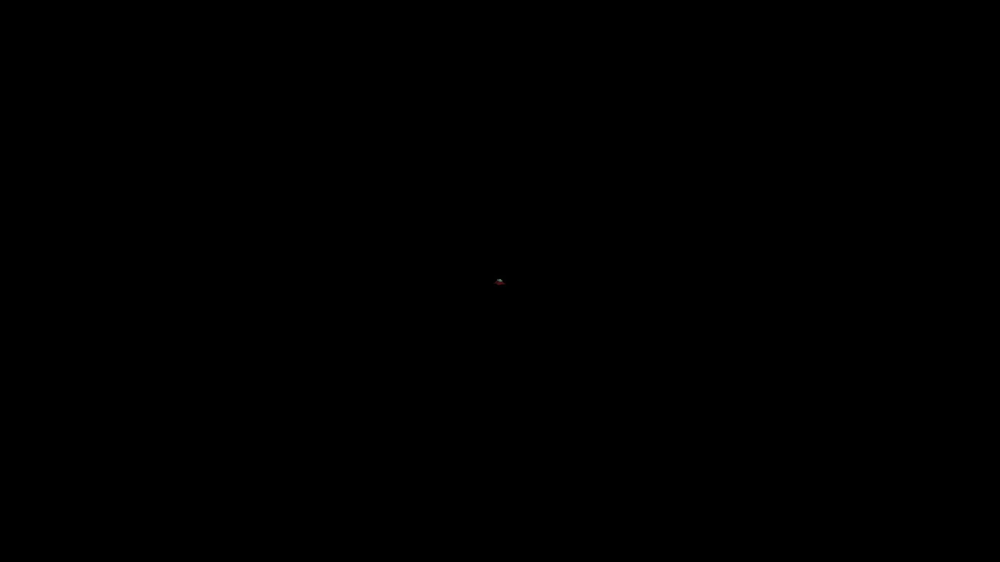

  │ 0:33 LogPython: X3DLAB: wrote toycar_x3d__Camera002_2__high (2 files, 7.8 s)
  │ 0:33 LogPython: X3DLAB: job 2/3 toycar_x3d__Camera003_2__high: opening /Game/X3DLab/toycar_x3d/Map_toycar_x3d
  │ 0:33 LogGlobalStatus: Browse Started Browse: "/Game/X3DLab/toycar_x3d/Map_toycar_x3d??game=/Script/MovieRenderPipelineCore.MoviePipelineGameMode"
  │ 0:33 LogNet: Browse: /Game/X3DLab/toycar_x3d/Map_toycar_x3d??game=/Script/MovieRenderPipelineCore.MoviePipelineGameMode
  │ 0:33 LogLoad: LoadMap: /Game/X3DLab/toycar_x3d/Map_toycar_x3d??game=/Script/MovieRenderPipelineCore.MoviePipelineGameMode
  │ 0:33 LogWorld: BeginTearingDown for /Game/X3DLab/toycar_x3d/Map_toycar_x3d
  │ 0:33 LogStaticMesh: Display: Waiting on static mesh StaticMesh /Game/X3DLab/toycar_x3d/ToyCar_2_IndexedTriangleSet.ToyCar_2_IndexedTriangleSet being ready before playing
  │ 0:33 LogStaticMesh: Display: Waiting on static mesh StaticMesh /Game/X3DLab/toycar_x3d/Glass_2_IndexedTriangleSet.Glass_2_IndexedTriangleSet being r

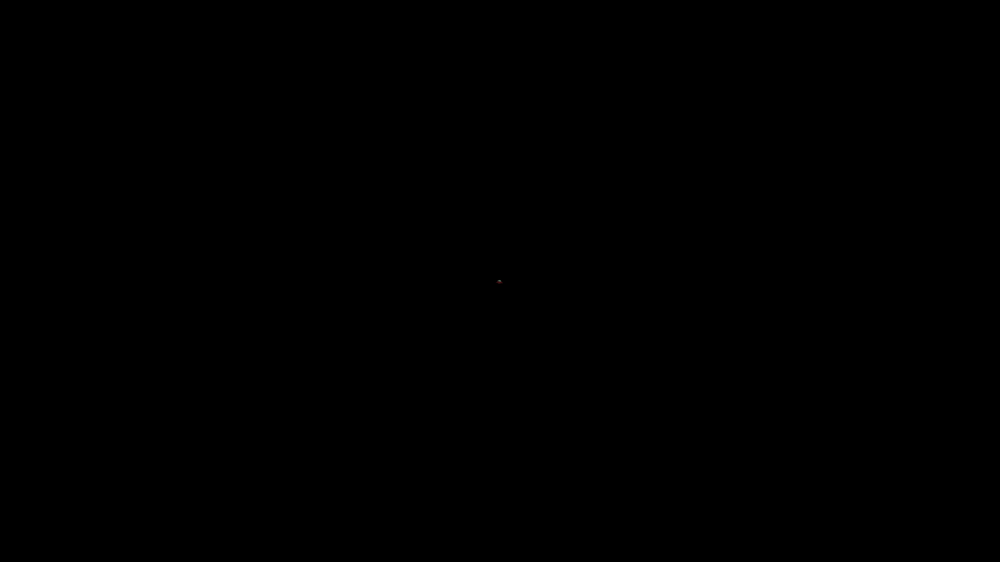

  │ 0:39 LogPython: X3DLAB: wrote toycar_x3d__Camera003_2__high (2 files, 6.1 s)
  │ 0:39 LogPython: X3DLAB: job 3/3 toycar_x3d__Camera004_2__high: opening /Game/X3DLab/toycar_x3d/Map_toycar_x3d
  │ 0:39 LogGlobalStatus: Browse Started Browse: "/Game/X3DLab/toycar_x3d/Map_toycar_x3d??game=/Script/MovieRenderPipelineCore.MoviePipelineGameMode"
  │ 0:39 LogNet: Browse: /Game/X3DLab/toycar_x3d/Map_toycar_x3d??game=/Script/MovieRenderPipelineCore.MoviePipelineGameMode
  │ 0:39 LogLoad: LoadMap: /Game/X3DLab/toycar_x3d/Map_toycar_x3d??game=/Script/MovieRenderPipelineCore.MoviePipelineGameMode
  │ 0:39 LogWorld: BeginTearingDown for /Game/X3DLab/toycar_x3d/Map_toycar_x3d
  │ 0:39 LogStaticMesh: Display: Waiting on static mesh StaticMesh /Game/X3DLab/toycar_x3d/Glass_2_IndexedTriangleSet.Glass_2_IndexedTriangleSet being ready before playing
  │ 0:39 LogStaticMesh: Display: Waiting on static mesh StaticMesh /Game/X3DLab/toycar_x3d/Fabric_2_IndexedTriangleSet.Fabric_2_IndexedTriangleSet being r

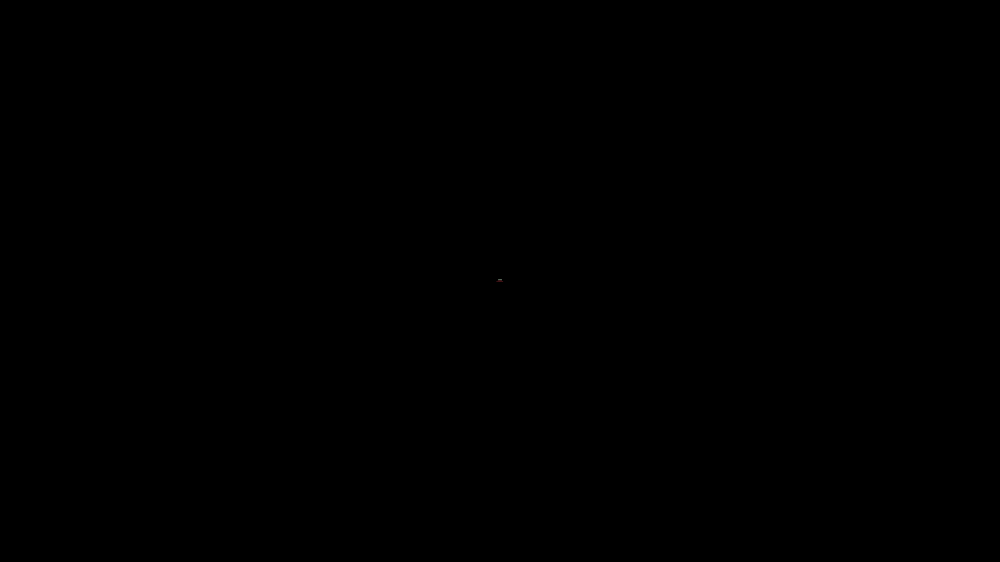

  │ 0:45 LogPython: X3DLAB: wrote toycar_x3d__Camera004_2__high (2 files, 5.9 s)
  │ 0:45 LogPython: X3DLAB: executor finished
  │ 0:45 LogWorld: BeginTearingDown for /Game/X3DLab/toycar_x3d/Map_toycar_x3d
  │ 0:45 LogSlate: Window 'X3DLab (64-bit Development SF_VULKAN_SM6) ' being destroyed
  │ 0:46 LogExit: Exiting.
■ render_toycar_x3d_high_cinematic: rc 0 in 0:50 · peak VRAM 4.3 GB, GPU up to 100%


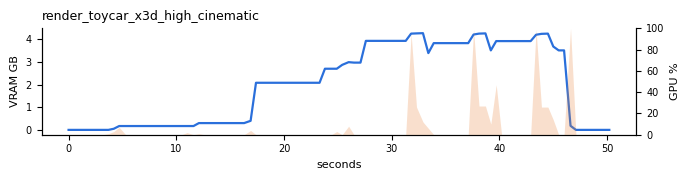

▶ render_toycar_gltf_high_cinematic
  │ 0:00 Failed to find game directory: /content/x3due/engine/X3DLab/Binaries
  │ 0:00 LogInit: Display: Running engine for game: X3DLab
  │ 0:00 LogCore: Display: Requested channels: 'cpu,gpu,frame,log,bookmark,screenshot,region'
  │ 0:00 LogCsvProfiler: Display: Metadata set : commandline="" /content/x3due/X3DLab/X3DLab.uproject /Game/X3DLab/toycar_gltf/Map_toycar_gltf -game -MoviePipelineLocalExecutorClass=/Script/MovieRenderPipelin…
  │ 0:01 LogConfig: No local boot hotfix file found at: [../../../../X3DLab/Saved/PersistentDownloadDir/HotfixForNextBoot.txt]
  │ 0:02 LogInit: Build: ++UE5+Release-5.4-CL-35576357
  │ 0:02 LogInit: Engine Version: 5.4.4-35576357+++UE5+Release-5.4
  │ 0:02 LogInit: Command Line: /Game/X3DLab/toycar_gltf/Map_toycar_gltf -game -MoviePipelineLocalExecutorClass=/Script/MovieRenderPipelineCore.MoviePipelinePythonHostExecutor -ExecutorPythonClass=/Engine/Pyt…
  │ 0:02 LogCoreRedirects: AddRedirect(/content/x3due/X3DLab/Sav

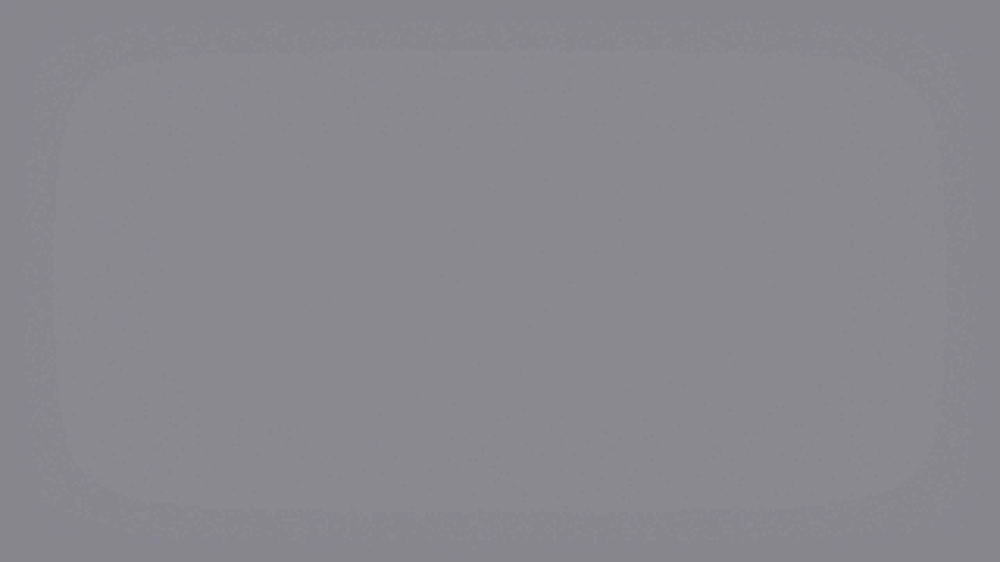

  │ 0:49 LogPython: X3DLAB: wrote toycar_gltf__x3dlab_auto__high (2 files, 21.0 s)
  │ 0:49 LogPython: X3DLAB: executor finished
  │ 0:49 LogWorld: BeginTearingDown for /Game/X3DLab/toycar_gltf/Map_toycar_gltf
  │ 0:49 LogSlate: Window 'X3DLab (64-bit Development SF_VULKAN_SM6) ' being destroyed
  │ 0:53 LogExit: Exiting.
■ render_toycar_gltf_high_cinematic: rc 0 in 0:55 · peak VRAM 4.3 GB, GPU up to 100%


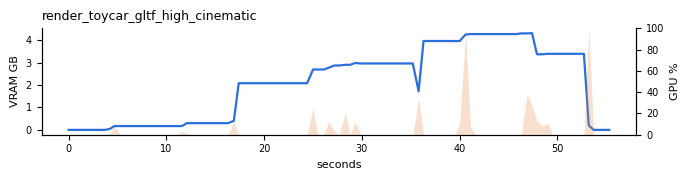

▶ render_odyssey_high_cinematic
  │ 0:00 Failed to find game directory: /content/x3due/engine/X3DLab/Binaries
  │ 0:00 LogInit: Display: Running engine for game: X3DLab
  │ 0:00 LogCore: Display: Requested channels: 'cpu,gpu,frame,log,bookmark,screenshot,region'
  │ 0:00 LogCsvProfiler: Display: Metadata set : commandline="" /content/x3due/X3DLab/X3DLab.uproject /Game/X3DLab/odyssey/Map_odyssey -game -MoviePipelineLocalExecutorClass=/Script/MovieRenderPipelineCore.Mo…
  │ 0:01 LogConfig: No local boot hotfix file found at: [../../../../X3DLab/Saved/PersistentDownloadDir/HotfixForNextBoot.txt]
  │ 0:02 LogInit: Build: ++UE5+Release-5.4-CL-35576357
  │ 0:02 LogInit: Engine Version: 5.4.4-35576357+++UE5+Release-5.4
  │ 0:02 LogInit: Command Line: /Game/X3DLab/odyssey/Map_odyssey -game -MoviePipelineLocalExecutorClass=/Script/MovieRenderPipelineCore.MoviePipelinePythonHostExecutor -ExecutorPythonClass=/Engine/PythonTypes…
  │ 0:02 LogCoreRedirects: AddRedirect(/content/x3due/X3DLab/Saved/C

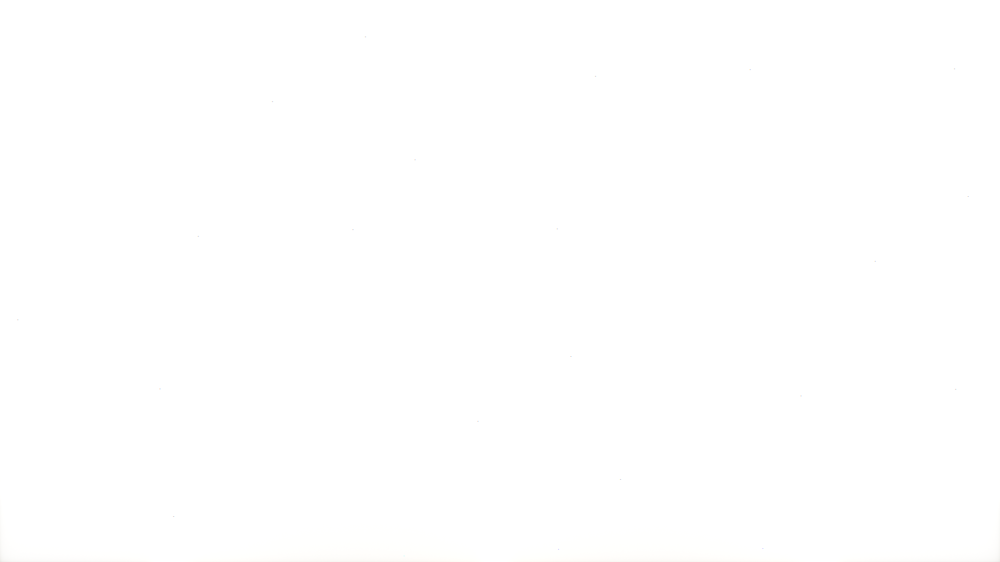

  │ 1:30 LogLoad: LoadMap: /Game/X3DLab/odyssey/Map_odyssey??game=/Script/MovieRenderPipelineCore.MoviePipelineGameMode
  │ 1:31 LogLoad: Took 0.799309 seconds to LoadMap(/Game/X3DLab/odyssey/Map_odyssey)
  │ 1:33 LogCore: Warning: Unable to statfs('/content/x3due/out/stills/odyssey.{ext}'): errno=2 (No such file or directory)
  │ 1:33 LogMovieRenderPipeline: [391] Finished processing Camera Cut [1/1].
  🖼 render_odyssey_high_cinematic · odyssey__GiftFrame__high.0000.png · 1:35


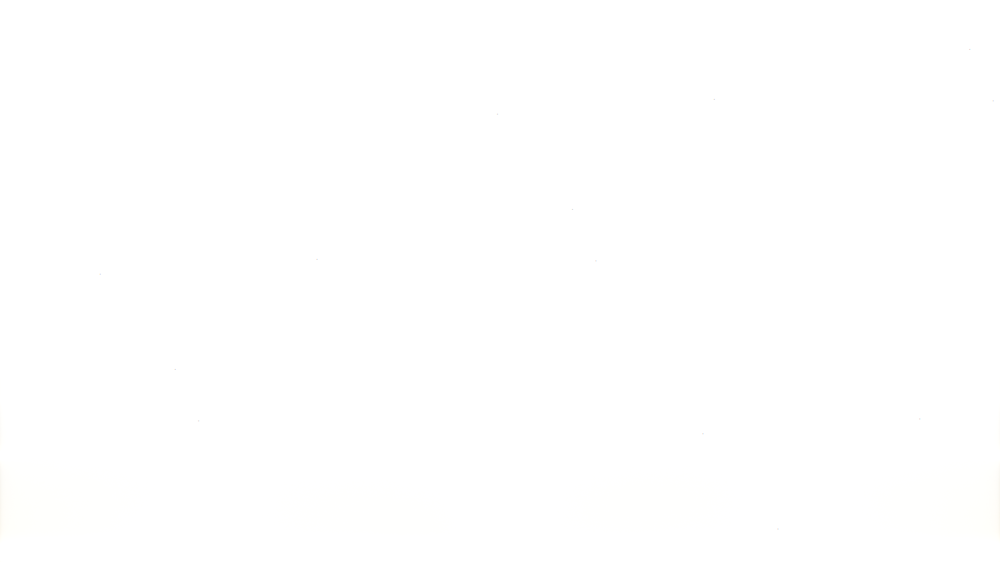

  │ 1:35 LogSlate: Window 'X3DLab (64-bit Development SF_VULKAN_SM6) ' being destroyed
  │ 1:35 LogShaderCompilers: Display: Shaders left to compile 0
  │ 1:36 LogExit: Exiting.
■ render_odyssey_high_cinematic: rc 0 in 1:40 · peak VRAM 4.5 GB, GPU up to 100%


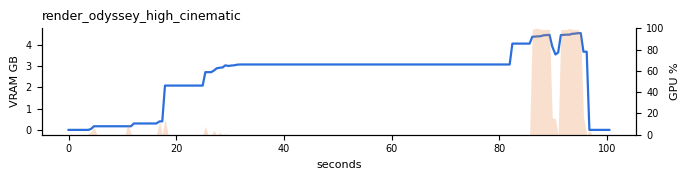

▶ render_gobbler3_high_cinematic
  │ 0:00 Failed to find game directory: /content/x3due/engine/X3DLab/Binaries
  │ 0:00 LogInit: Display: Running engine for game: X3DLab
  │ 0:00 LogCore: Display: Requested channels: 'cpu,gpu,frame,log,bookmark,screenshot,region'
  │ 0:00 LogCsvProfiler: Display: Metadata set : commandline="" /content/x3due/X3DLab/X3DLab.uproject /Game/X3DLab/gobbler3/Map_gobbler3 -game -MoviePipelineLocalExecutorClass=/Script/MovieRenderPipelineCore.…
  │ 0:01 LogConfig: No local boot hotfix file found at: [../../../../X3DLab/Saved/PersistentDownloadDir/HotfixForNextBoot.txt]
  │ 0:02 LogInit: Build: ++UE5+Release-5.4-CL-35576357
  │ 0:02 LogInit: Engine Version: 5.4.4-35576357+++UE5+Release-5.4
  │ 0:02 LogInit: Command Line: /Game/X3DLab/gobbler3/Map_gobbler3 -game -MoviePipelineLocalExecutorClass=/Script/MovieRenderPipelineCore.MoviePipelinePythonHostExecutor -ExecutorPythonClass=/Engine/PythonTyp…
  │ 0:02 LogCoreRedirects: AddRedirect(/content/x3due/X3DLab/Saved/

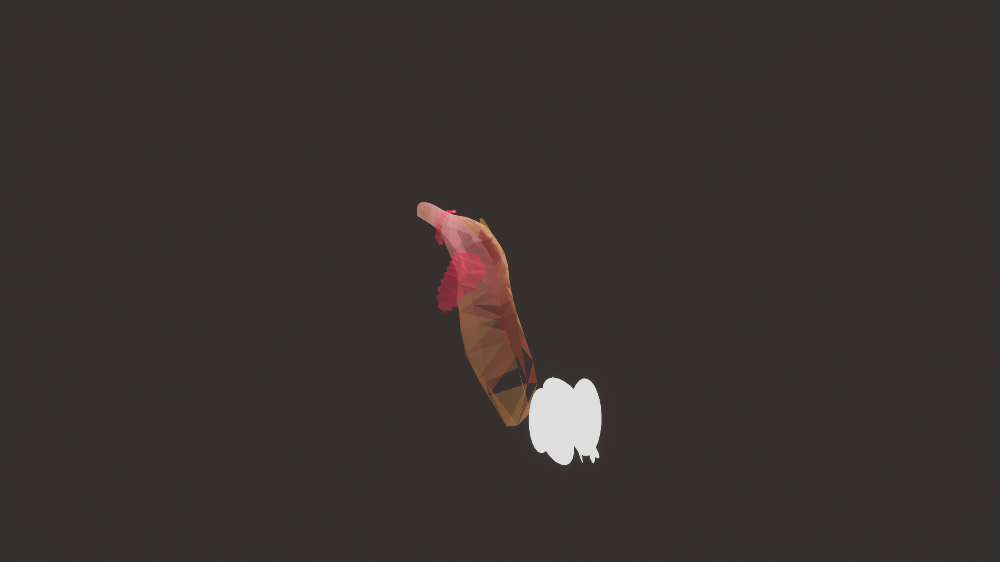

  │ 0:40 LogPython: X3DLAB: wrote gobbler3__Colossus__high (2 files, 14.4 s)
  │ 0:40 LogPython: X3DLAB: job 2/4 gobbler3__Crown__high: opening /Game/X3DLab/gobbler3/Map_gobbler3
  │ 0:40 LogGlobalStatus: Browse Started Browse: "/Game/X3DLab/gobbler3/Map_gobbler3??game=/Script/MovieRenderPipelineCore.MoviePipelineGameMode"
  │ 0:40 LogNet: Browse: /Game/X3DLab/gobbler3/Map_gobbler3??game=/Script/MovieRenderPipelineCore.MoviePipelineGameMode
  │ 0:40 LogLoad: LoadMap: /Game/X3DLab/gobbler3/Map_gobbler3??game=/Script/MovieRenderPipelineCore.MoviePipelineGameMode
  │ 0:40 LogWorld: BeginTearingDown for /Game/X3DLab/gobbler3/Map_gobbler3
  │ 0:40 LogStaticMesh: Display: Waiting on static mesh StaticMesh /Game/X3DLab/gobbler3/Shape_Sphere.Shape_Sphere being ready before playing
  │ 0:40 LogStaticMesh: Display: Waiting on static mesh StaticMesh /Game/X3DLab/gobbler3/PickMarker_Sphere_001.PickMarker_Sphere_001 being ready before playing
  │ 0:40 LogStaticMesh: Display: Waiting on static mesh 

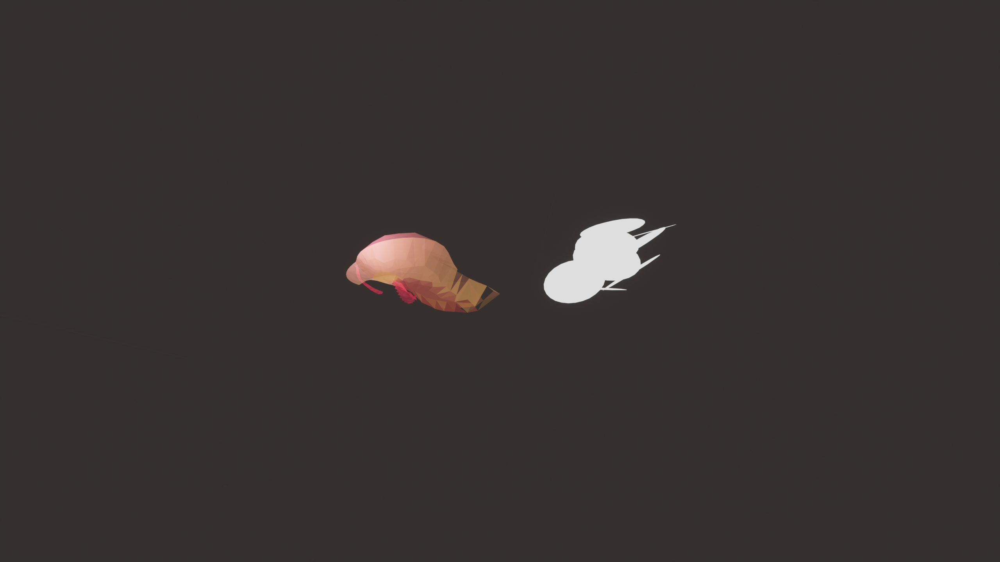

  │ 0:53 LogPython: X3DLAB: wrote gobbler3__Crown__high (2 files, 12.3 s)
  │ 0:53 LogPython: X3DLAB: job 3/4 gobbler3__EyeToEye__high: opening /Game/X3DLab/gobbler3/Map_gobbler3
  │ 0:53 LogGlobalStatus: Browse Started Browse: "/Game/X3DLab/gobbler3/Map_gobbler3??game=/Script/MovieRenderPipelineCore.MoviePipelineGameMode"
  │ 0:53 LogNet: Browse: /Game/X3DLab/gobbler3/Map_gobbler3??game=/Script/MovieRenderPipelineCore.MoviePipelineGameMode
  │ 0:53 LogLoad: LoadMap: /Game/X3DLab/gobbler3/Map_gobbler3??game=/Script/MovieRenderPipelineCore.MoviePipelineGameMode
  │ 0:53 LogWorld: BeginTearingDown for /Game/X3DLab/gobbler3/Map_gobbler3
  │ 0:53 LogStaticMesh: Display: Waiting on static mesh StaticMesh /Game/X3DLab/gobbler3/Gobble_IndexedFaceSet_001.Gobble_IndexedFaceSet_001 being ready before playing
  │ 0:53 LogStaticMesh: Display: Waiting on static mesh StaticMesh /Game/X3DLab/gobbler3/Gobble_IndexedFaceSet.Gobble_IndexedFaceSet being ready before playing
  │ 0:53 LogStaticMesh: Displa

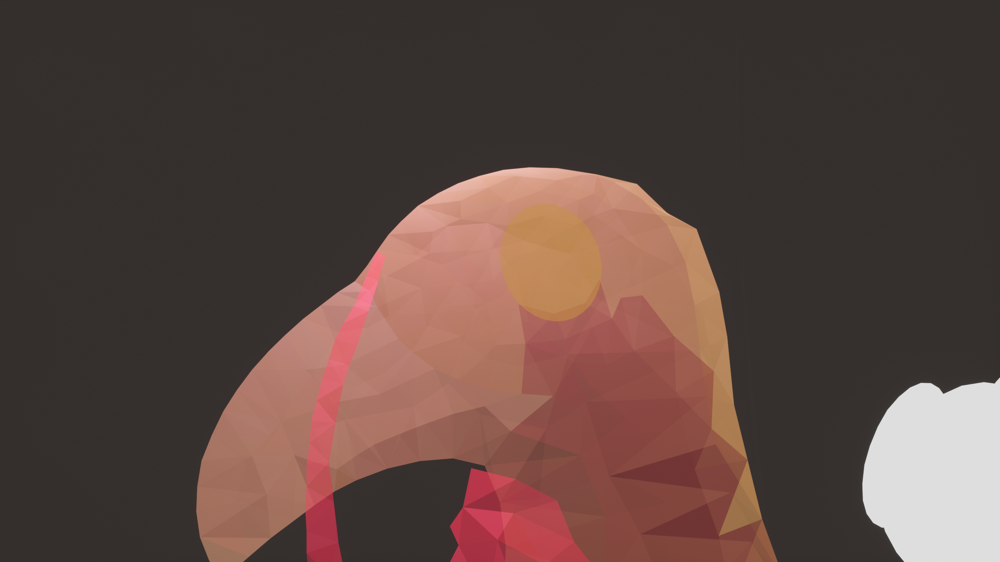

  │ 1:05 LogPython: X3DLAB: wrote gobbler3__EyeToEye__high (2 files, 12.5 s)
  │ 1:05 LogPython: X3DLAB: job 4/4 gobbler3__Flywheel__high: opening /Game/X3DLab/gobbler3/Map_gobbler3
  │ 1:05 LogGlobalStatus: Browse Started Browse: "/Game/X3DLab/gobbler3/Map_gobbler3??game=/Script/MovieRenderPipelineCore.MoviePipelineGameMode"
  │ 1:05 LogNet: Browse: /Game/X3DLab/gobbler3/Map_gobbler3??game=/Script/MovieRenderPipelineCore.MoviePipelineGameMode
  │ 1:05 LogLoad: LoadMap: /Game/X3DLab/gobbler3/Map_gobbler3??game=/Script/MovieRenderPipelineCore.MoviePipelineGameMode
  │ 1:05 LogWorld: BeginTearingDown for /Game/X3DLab/gobbler3/Map_gobbler3
  │ 1:05 LogStaticMesh: Display: Waiting on static mesh StaticMesh /Game/X3DLab/gobbler3/Shape_Sphere.Shape_Sphere being ready before playing
  │ 1:05 LogStaticMesh: Display: Waiting on static mesh StaticMesh /Game/X3DLab/gobbler3/Gobble_IndexedFaceSet_001.Gobble_IndexedFaceSet_001 being ready before playing
  │ 1:05 LogStaticMesh: Display: Waiting on s

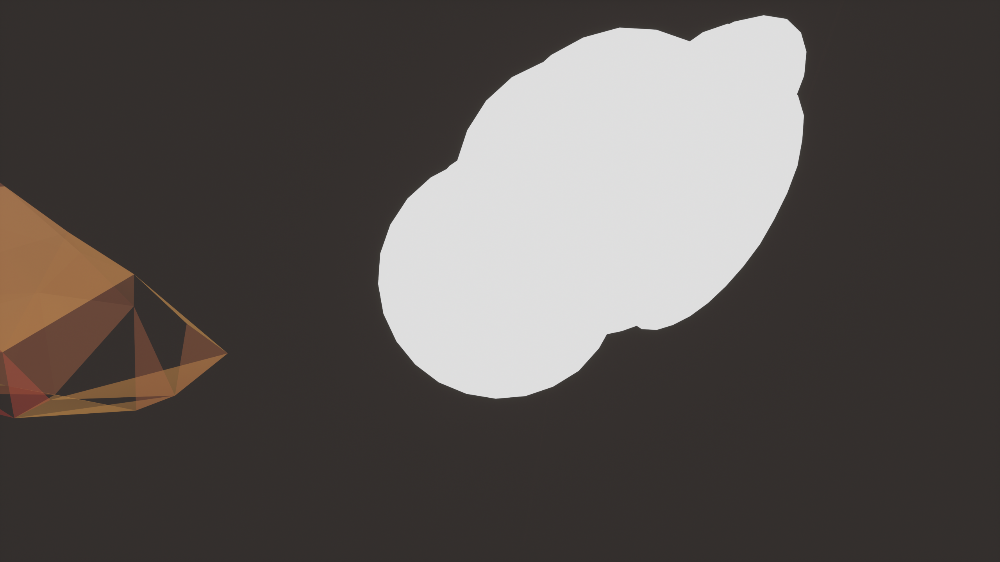

  │ 1:17 LogPython: X3DLAB: wrote gobbler3__Flywheel__high (2 files, 12.2 s)
  │ 1:17 LogPython: X3DLAB: executor finished
  │ 1:17 LogWorld: BeginTearingDown for /Game/X3DLab/gobbler3/Map_gobbler3
  │ 1:17 LogSlate: Window 'X3DLab (64-bit Development SF_VULKAN_SM6) ' being destroyed
  │ 1:18 LogShaderCompilers: Display: Shaders left to compile 0
  ⏱ 1:21 · shaders: 0 jobs done, 0 left · 0 workers · Unreal 2.4 GB · RAM 4.1/53 GB · VRAM 3.6/22 GB · GPU 0% · disk 177 GB free
  │ 1:21 LogExit: Exiting.
■ render_gobbler3_high_cinematic: rc 0 in 1:25 · peak VRAM 4.3 GB, GPU up to 100%


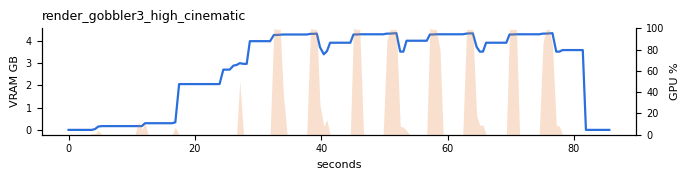

In [20]:
#@title 9 · Render { display-mode: "form" }
rung_name = RUNG if RUNG != "auto" else ("ultra" if HW["vram_gb"] >= 36 else "high")
if rung_name not in PLAN["ladder"]:
    rung_name = "ultra"
RUNG_USED = PLAN["ladder"][rung_name]
print("rung %s: %dx%d · %s · %s spatial x %s temporal samples · textures %s" % (rung_name, *RUNG_USED["resolution"], RUNG_USED["renderer"],
      RUNG_USED["spatial_samples"], RUNG_USED["temporal_samples"], RUNG_USED["texture_streaming"]))
RND = {}
for n, res in IMP.items():
    if n == "calib" or n.endswith("_usd") or not res["report"].get("ok"):
        continue
    cams = staging.pick(sorted(res["report"]["sequences"]), SCN.get(n, {}).get("framing", {}), MAX_VIEWPOINTS)
    out = pipeline.render(LAB, n, cams, rung_name, RUNG_USED, look=LOOK)
    RND[n] = out
    ok = [s for s in out["stills"] if s["png"] or s["exr"]]
    p = out["proof"]
    gpu = out.get("gpu") or {}
    per = [s["seconds"] for s in out["stills"] if s.get("seconds")]
    SC.add("9 render", "%s: stills" % n, "PASS" if len(ok) == len(cams) and cams else "FAIL" if not ok else "WARN",
           "%d/%d viewpoints · %s · %.0f s per still (first %.0f s) · peak VRAM %.1f GB" % (
               len(ok), len(cams), p.get("why"), (sum(per[1:]) / len(per[1:])) if len(per) > 1 else (per[0] if per else 0),
               per[0] if per else 0, (gpu.get("peak_mem_mb") or 0) / 1024))
    if not ok:
        print("--- %s: the log lines that matter ---\n%s" % (n, out["excerpt"][-3000:]))
    for s in ok[:2]:
        if s["png"] and not (LAB.live and s["png"] in LAB.live.shown):      # VISUAL already showed it live
            display(IPImage(filename=s["png"], width=640))
CARD["renders"] = {n: {"rung": rung_name, "settings": RUNG_USED, "seconds": r["seconds"], "gpu": r.get("gpu"), "proof": r["proof"],
                       "stills": [{k: v for k, v in s.items() if k != "files"} for s in r["stills"]], "attempts": r["attempts"]}
                   for n, r in RND.items()}

## 10 · Unreal vs X_ITE vs Cycles

The same viewpoints, the same size, on the lab's flat magenta key background: Unreal (match look, key backdrop), X_ITE in headless Chrome on the GPU (the scene with its ROUTEs removed, so every engine shows the authored, time-0 state), and Cycles for the first viewpoint. Judged with **`x3dlab.formats.compare_pngs`** (`match`: silhouette agreement forgiving 2 pixels; colour delta and its 64/255 threshold, because Phong vs PBR alone moves colours by 30–50) plus SSIM. The contact sheet puts them side by side.

19:15:38 INFO  install   playwright install chromium (48583 ms)
19:15:38 INFO  install   download X_ITE 16.7.0 from npm (501 ms)
19:15:40 INFO  browser   headless Chromium 158.0.8127.18 · X_ITE 16.7.0 · ANGLE (NVIDIA, Vulkan 1.4.312 (NVIDIA NVIDIA L4 (0x000027B8)), NVIDIA)
X_ITE renderer: ANGLE (NVIDIA, Vulkan 1.4.312 (NVIDIA NVIDIA L4 (0x000027B8)), NVIDIA)
▶ render_stilllife_preview_match_key
  │ 0:00 Failed to find game directory: /content/x3due/engine/X3DLab/Binaries
  │ 0:00 LogInit: Display: Running engine for game: X3DLab
  │ 0:00 LogCore: Display: Requested channels: 'cpu,gpu,frame,log,bookmark,screenshot,region'
  │ 0:00 LogCsvProfiler: Display: Metadata set : commandline="" /content/x3due/X3DLab/X3DLab.uproject /Game/X3DLab/stilllife/Map_stilllife -game -MoviePipelineLocalExecutorClass=/Script/MovieRenderPipelineCor…
  │ 0:01 LogConfig: No local boot hotfix file found at: [../../../../X3DLab/Saved/PersistentDownloadDir/HotfixForNextBoot.txt]
  │ 0:02 LogInit: Build: ++UE5+Rel

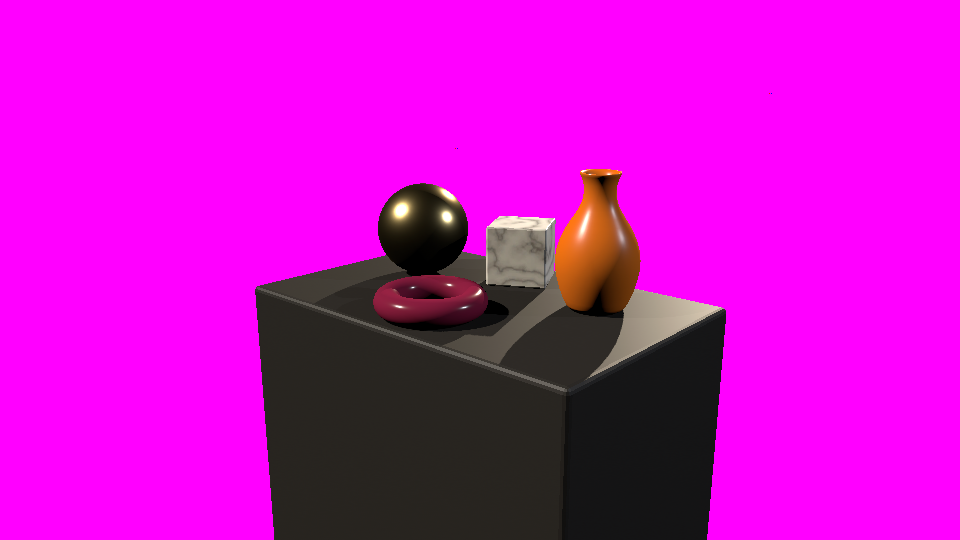

  │ 0:28 LogPython: X3DLAB: wrote stilllife__CA_Camera__preview__key (1 files, 4.1 s)
  │ 0:28 LogPython: X3DLAB: executor finished
  │ 0:28 LogWorld: BeginTearingDown for /Game/X3DLab/stilllife/Map_stilllife
  │ 0:28 LogSlate: Window 'X3DLab (64-bit Development SF_VULKAN_SM6) ' being destroyed
  │ 0:29 LogExit: Exiting.
■ render_stilllife_preview_match_key: rc 0 in 0:30 · peak VRAM 4.2 GB, GPU up to 100%


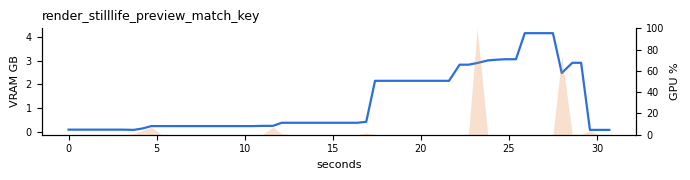

19:16:19 INFO  blender   render render ok (3.2 s)
▶ render_toycar_x3d_preview_match_key
  │ 0:00 Failed to find game directory: /content/x3due/engine/X3DLab/Binaries
  │ 0:00 LogInit: Display: Running engine for game: X3DLab
  │ 0:00 LogCore: Display: Requested channels: 'cpu,gpu,frame,log,bookmark,screenshot,region'
  │ 0:00 LogCsvProfiler: Display: Metadata set : commandline="" /content/x3due/X3DLab/X3DLab.uproject /Game/X3DLab/toycar_x3d/Map_toycar_x3d -game -MoviePipelineLocalExecutorClass=/Script/MovieRenderPipelineC…
  │ 0:01 LogConfig: No local boot hotfix file found at: [../../../../X3DLab/Saved/PersistentDownloadDir/HotfixForNextBoot.txt]
  │ 0:02 LogInit: Build: ++UE5+Release-5.4-CL-35576357
  │ 0:02 LogInit: Engine Version: 5.4.4-35576357+++UE5+Release-5.4
  │ 0:02 LogInit: Command Line: /Game/X3DLab/toycar_x3d/Map_toycar_x3d -game -MoviePipelineLocalExecutorClass=/Script/MovieRenderPipelineCore.MoviePipelinePythonHostExecutor -ExecutorPythonClass=/Engine/Pytho…
  │ 0:02 Log

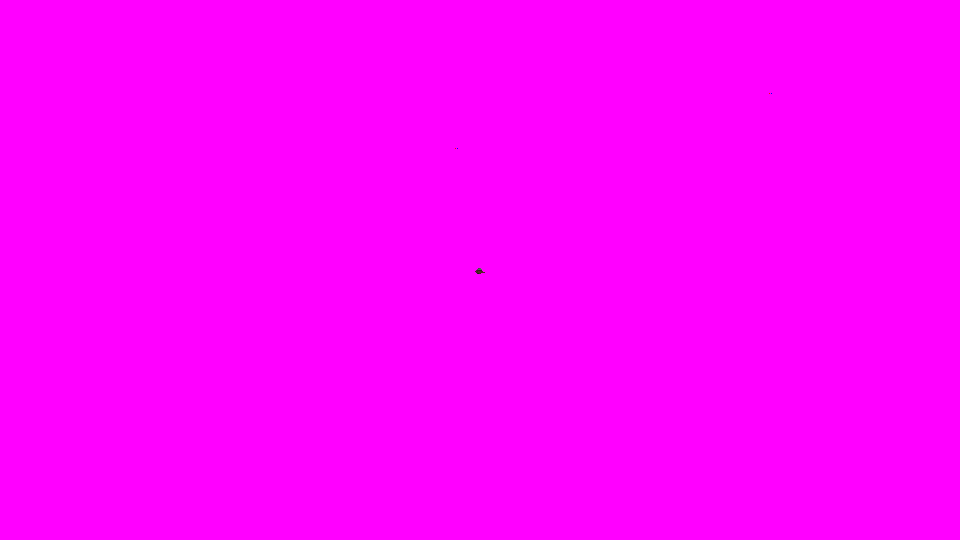

  │ 0:29 LogPython: X3DLAB: wrote toycar_x3d__Camera002_2__preview__key (1 files, 5.6 s)
  │ 0:29 LogPython: X3DLAB: job 2/3 toycar_x3d__Camera003_2__preview__key: opening /Game/X3DLab/toycar_x3d/Map_toycar_x3d
  │ 0:29 LogGlobalStatus: Browse Started Browse: "/Game/X3DLab/toycar_x3d/Map_toycar_x3d??game=/Script/MovieRenderPipelineCore.MoviePipelineGameMode"
  │ 0:29 LogNet: Browse: /Game/X3DLab/toycar_x3d/Map_toycar_x3d??game=/Script/MovieRenderPipelineCore.MoviePipelineGameMode
  │ 0:29 LogLoad: LoadMap: /Game/X3DLab/toycar_x3d/Map_toycar_x3d??game=/Script/MovieRenderPipelineCore.MoviePipelineGameMode
  │ 0:29 LogWorld: BeginTearingDown for /Game/X3DLab/toycar_x3d/Map_toycar_x3d
  │ 0:29 LogStaticMesh: Display: Waiting on static mesh StaticMesh /Game/X3DLab/toycar_x3d/ToyCar_2_IndexedTriangleSet.ToyCar_2_IndexedTriangleSet being ready before playing
  │ 0:29 LogStaticMesh: Display: Waiting on static mesh StaticMesh /Game/X3DLab/toycar_x3d/Glass_2_IndexedTriangleSet.Glass_2_IndexedTri

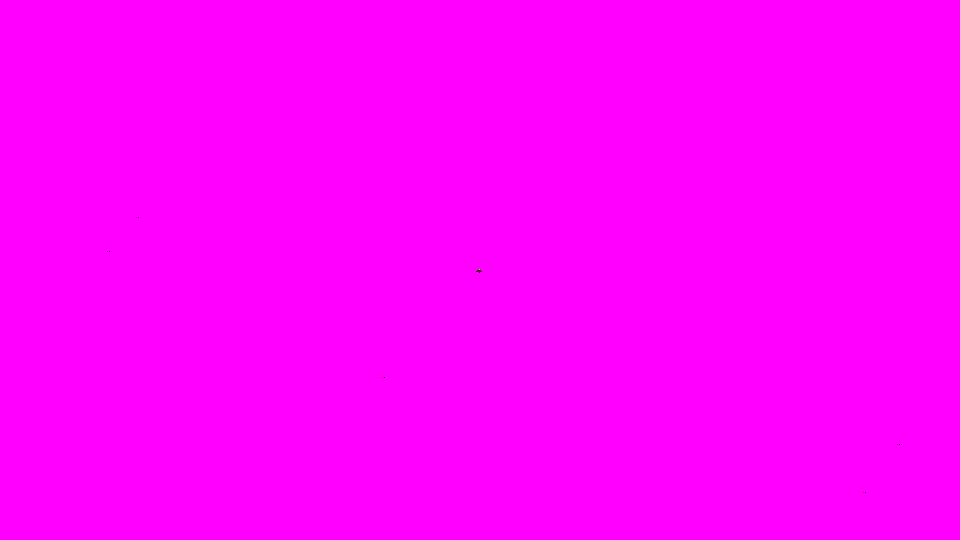

  │ 0:29 LogPython: X3DLAB: wrote toycar_x3d__Camera003_2__preview__key (1 files, 0.5 s)
  │ 0:29 LogPython: X3DLAB: job 3/3 toycar_x3d__Camera004_2__preview__key: opening /Game/X3DLab/toycar_x3d/Map_toycar_x3d
  │ 0:29 LogGlobalStatus: Browse Started Browse: "/Game/X3DLab/toycar_x3d/Map_toycar_x3d??game=/Script/MovieRenderPipelineCore.MoviePipelineGameMode"
  │ 0:29 LogNet: Browse: /Game/X3DLab/toycar_x3d/Map_toycar_x3d??game=/Script/MovieRenderPipelineCore.MoviePipelineGameMode
  │ 0:29 LogLoad: LoadMap: /Game/X3DLab/toycar_x3d/Map_toycar_x3d??game=/Script/MovieRenderPipelineCore.MoviePipelineGameMode
  │ 0:29 LogWorld: BeginTearingDown for /Game/X3DLab/toycar_x3d/Map_toycar_x3d
  │ 0:29 LogStaticMesh: Display: Waiting on static mesh StaticMesh /Game/X3DLab/toycar_x3d/Glass_2_IndexedTriangleSet.Glass_2_IndexedTriangleSet being ready before playing
  │ 0:29 LogStaticMesh: Display: Waiting on static mesh StaticMesh /Game/X3DLab/toycar_x3d/Fabric_2_IndexedTriangleSet.Fabric_2_IndexedTri

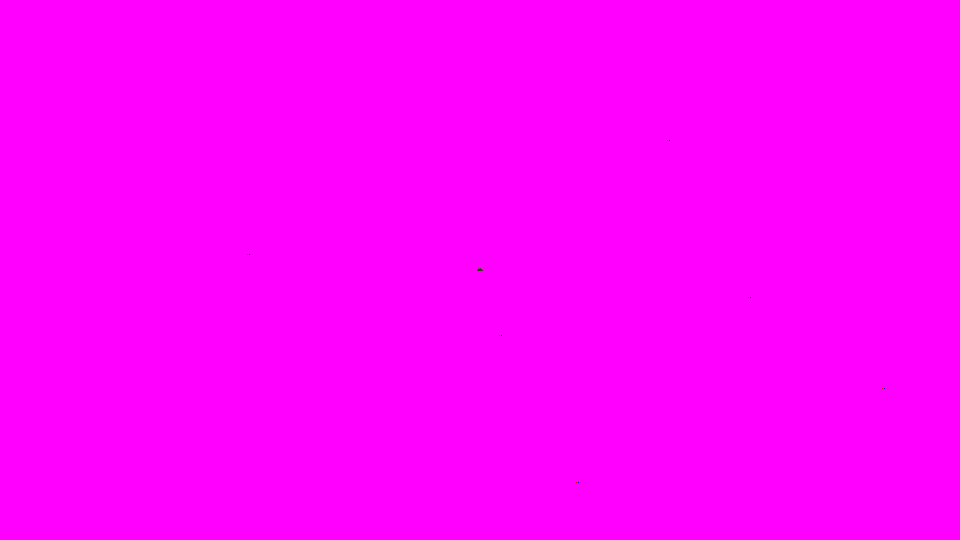

  │ 0:29 LogPython: X3DLAB: wrote toycar_x3d__Camera004_2__preview__key (1 files, 0.3 s)
  │ 0:29 LogPython: X3DLAB: executor finished
  │ 0:29 LogWorld: BeginTearingDown for /Game/X3DLab/toycar_x3d/Map_toycar_x3d
  │ 0:29 LogSlate: Window 'X3DLab (64-bit Development SF_VULKAN_SM6) ' being destroyed
  │ 0:30 LogExit: Exiting.
■ render_toycar_x3d_preview_match_key: rc 0 in 0:35 · peak VRAM 4.2 GB, GPU up to 97%


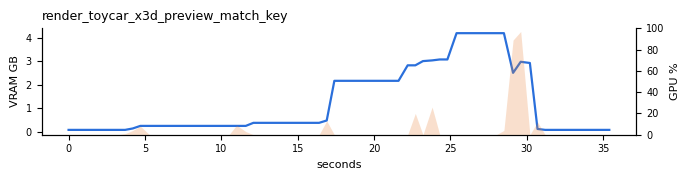

19:17:46 INFO  blender   render render ok (2.4 s)
▶ render_toycar_gltf_preview_match_key
  │ 0:00 Failed to find game directory: /content/x3due/engine/X3DLab/Binaries
  │ 0:00 LogInit: Display: Running engine for game: X3DLab
  │ 0:00 LogCore: Display: Requested channels: 'cpu,gpu,frame,log,bookmark,screenshot,region'
  │ 0:00 LogCsvProfiler: Display: Metadata set : commandline="" /content/x3due/X3DLab/X3DLab.uproject /Game/X3DLab/toycar_gltf/Map_toycar_gltf -game -MoviePipelineLocalExecutorClass=/Script/MovieRenderPipelin…
  │ 0:01 LogConfig: No local boot hotfix file found at: [../../../../X3DLab/Saved/PersistentDownloadDir/HotfixForNextBoot.txt]
  │ 0:02 LogInit: Build: ++UE5+Release-5.4-CL-35576357
  │ 0:02 LogInit: Engine Version: 5.4.4-35576357+++UE5+Release-5.4
  │ 0:02 LogInit: Command Line: /Game/X3DLab/toycar_gltf/Map_toycar_gltf -game -MoviePipelineLocalExecutorClass=/Script/MovieRenderPipelineCore.MoviePipelinePythonHostExecutor -ExecutorPythonClass=/Engine/Pyt…
  │ 0:02 Lo

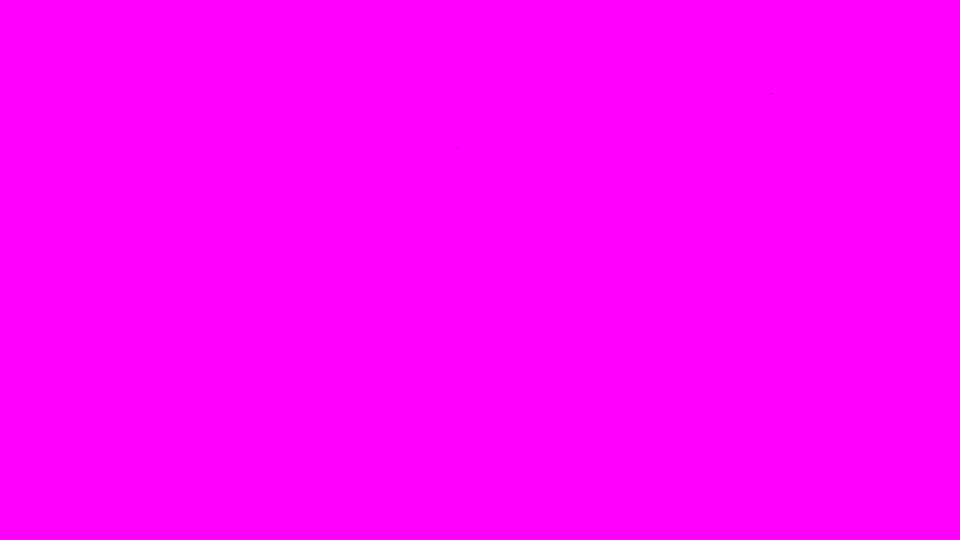

  │ 0:34 LogPython: X3DLAB: wrote toycar_gltf__x3dlab_auto__preview__key (1 files, 10.8 s)
  │ 0:34 LogPython: X3DLAB: executor finished
  │ 0:34 LogWorld: BeginTearingDown for /Game/X3DLab/toycar_gltf/Map_toycar_gltf
  │ 0:34 LogSlate: Window 'X3DLab (64-bit Development SF_VULKAN_SM6) ' being destroyed
  │ 0:38 LogExit: Exiting.
  ⏱ 0:40 · shaders: 0 jobs done, 0 left · 0 workers · RAM 3.2/53 GB · VRAM 0.1/22 GB · GPU 0% · disk 176 GB free
■ render_toycar_gltf_preview_match_key: rc 0 in 0:40 · peak VRAM 4.2 GB, GPU up to 100%


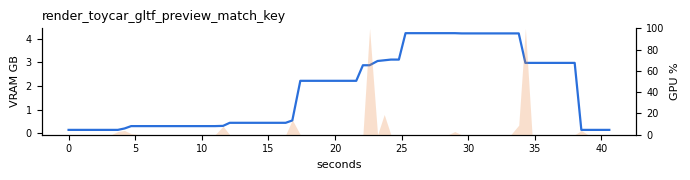

▶ render_odyssey_preview_match_key
  │ 0:00 Failed to find game directory: /content/x3due/engine/X3DLab/Binaries
  │ 0:00 LogInit: Display: Running engine for game: X3DLab
  │ 0:00 LogCore: Display: Requested channels: 'cpu,gpu,frame,log,bookmark,screenshot,region'
  │ 0:00 LogCsvProfiler: Display: Metadata set : commandline="" /content/x3due/X3DLab/X3DLab.uproject /Game/X3DLab/odyssey/Map_odyssey -game -MoviePipelineLocalExecutorClass=/Script/MovieRenderPipelineCore.Mo…
  │ 0:01 LogConfig: No local boot hotfix file found at: [../../../../X3DLab/Saved/PersistentDownloadDir/HotfixForNextBoot.txt]
  │ 0:02 LogInit: Build: ++UE5+Release-5.4-CL-35576357
  │ 0:02 LogInit: Engine Version: 5.4.4-35576357+++UE5+Release-5.4
  │ 0:02 LogInit: Command Line: /Game/X3DLab/odyssey/Map_odyssey -game -MoviePipelineLocalExecutorClass=/Script/MovieRenderPipelineCore.MoviePipelinePythonHostExecutor -ExecutorPythonClass=/Engine/PythonTypes…
  │ 0:02 LogCoreRedirects: AddRedirect(/content/x3due/X3DLab/Save

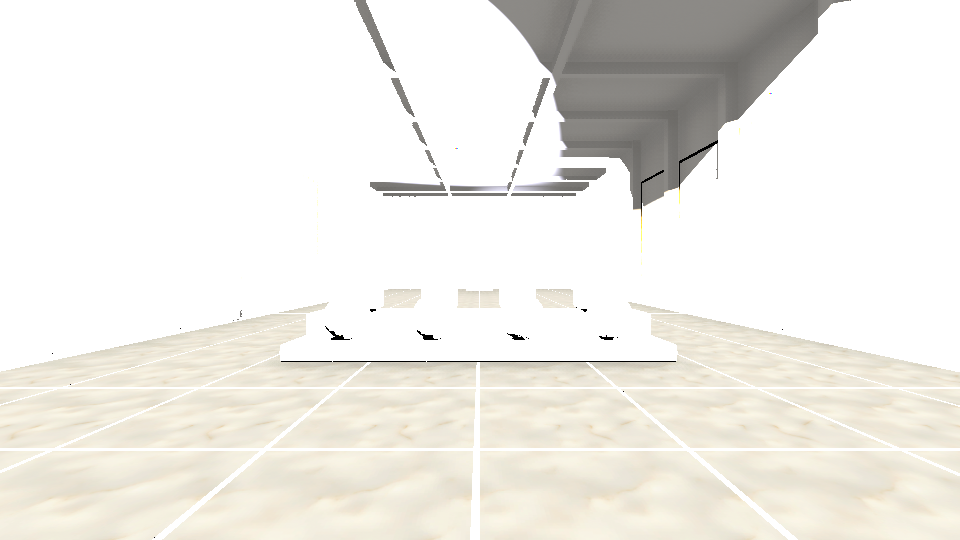

  │ 0:30 LogLoad: LoadMap: /Game/X3DLab/odyssey/Map_odyssey??game=/Script/MovieRenderPipelineCore.MoviePipelineGameMode
  │ 0:36 LogMovieRenderPipeline: Applying CVar "r.DepthOfFieldQuality" PreviousValue: 4.000000 NewValue: 0.000000
  │ 0:36 LogCore: Warning: Unable to statfs('/content/x3due/out/stills/odyssey/odyssey__GiftFrame__preview__key.0000.{ext}'): errno=2 (No such file or directory)
  │ 0:36 LogLoad: Took 5.420836 seconds to LoadMap(/Game/X3DLab/odyssey/Map_odyssey)
  ⏱ 0:41 · Unreal 3.0 GB · RAM 5.6/53 GB · VRAM 3.4/22 GB · GPU 100% · disk 176 GB free
  │ 0:46 Assertion failed: bSuccess [File:./Runtime/VulkanRHI/Private/VulkanCommandBuffer.cpp] [Line: 503]
  │ 0:46 LogCore: Error: appError called: Assertion failed: bSuccess [File:./Runtime/VulkanRHI/Private/VulkanCommandBuffer.cpp] [Line: 503]
  │ 0:46 Unhandled Exception: SIGSEGV: invalid attempt to write memory at address 0x0000000000000003
  │ 0:46 LogCore: Assertion failed: bSuccess [File:./Runtime/VulkanRHI/Private/Vulk

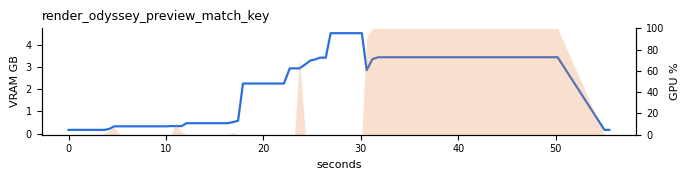

19:19:54 INFO  blender   render render ok (10.2 s)
▶ render_gobbler3_preview_match_key
  │ 0:00 Failed to find game directory: /content/x3due/engine/X3DLab/Binaries
  │ 0:00 LogInit: Display: Running engine for game: X3DLab
  │ 0:00 LogCore: Display: Requested channels: 'cpu,gpu,frame,log,bookmark,screenshot,region'
  │ 0:00 LogCsvProfiler: Display: Metadata set : commandline="" /content/x3due/X3DLab/X3DLab.uproject /Game/X3DLab/gobbler3/Map_gobbler3 -game -MoviePipelineLocalExecutorClass=/Script/MovieRenderPipelineCore.…
  │ 0:01 LogConfig: No local boot hotfix file found at: [../../../../X3DLab/Saved/PersistentDownloadDir/HotfixForNextBoot.txt]
  │ 0:03 LogInit: Build: ++UE5+Release-5.4-CL-35576357
  │ 0:03 LogInit: Engine Version: 5.4.4-35576357+++UE5+Release-5.4
  │ 0:03 LogInit: Command Line: /Game/X3DLab/gobbler3/Map_gobbler3 -game -MoviePipelineLocalExecutorClass=/Script/MovieRenderPipelineCore.MoviePipelinePythonHostExecutor -ExecutorPythonClass=/Engine/PythonTyp…
  │ 0:03 LogC

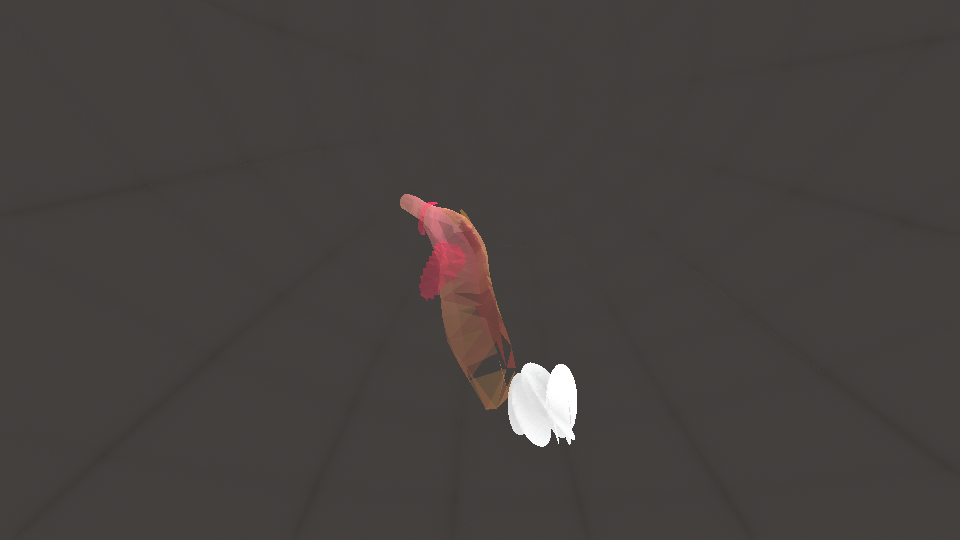

  │ 0:35 LogPython: X3DLAB: wrote gobbler3__Colossus__preview__key (1 files, 10.0 s)
  │ 0:35 LogPython: X3DLAB: job 2/4 gobbler3__Crown__preview__key: opening /Game/X3DLab/gobbler3/Map_gobbler3
  │ 0:35 LogGlobalStatus: Browse Started Browse: "/Game/X3DLab/gobbler3/Map_gobbler3??game=/Script/MovieRenderPipelineCore.MoviePipelineGameMode"
  │ 0:35 LogNet: Browse: /Game/X3DLab/gobbler3/Map_gobbler3??game=/Script/MovieRenderPipelineCore.MoviePipelineGameMode
  │ 0:35 LogLoad: LoadMap: /Game/X3DLab/gobbler3/Map_gobbler3??game=/Script/MovieRenderPipelineCore.MoviePipelineGameMode
  │ 0:35 LogWorld: BeginTearingDown for /Game/X3DLab/gobbler3/Map_gobbler3
  │ 0:35 LogShaderCompilers: Display: Cancelled job 0x0xb8150175800 with pending SubmitJob call.
  │ 0:35 LogStaticMesh: Display: Waiting on static mesh StaticMesh /Game/X3DLab/gobbler3/Shape_Sphere.Shape_Sphere being ready before playing
  │ 0:35 LogStaticMesh: Display: Waiting on static mesh StaticMesh /Game/X3DLab/gobbler3/PickMarker_Sph

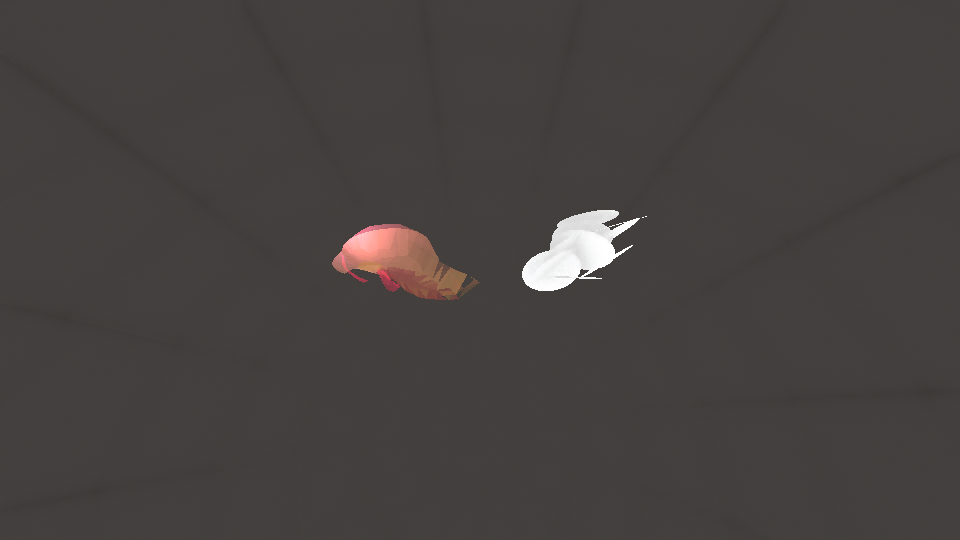

  │ 0:43 LogPython: X3DLAB: wrote gobbler3__Crown__preview__key (1 files, 8.2 s)
  │ 0:43 LogPython: X3DLAB: job 3/4 gobbler3__EyeToEye__preview__key: opening /Game/X3DLab/gobbler3/Map_gobbler3
  │ 0:43 LogGlobalStatus: Browse Started Browse: "/Game/X3DLab/gobbler3/Map_gobbler3??game=/Script/MovieRenderPipelineCore.MoviePipelineGameMode"
  │ 0:43 LogNet: Browse: /Game/X3DLab/gobbler3/Map_gobbler3??game=/Script/MovieRenderPipelineCore.MoviePipelineGameMode
  │ 0:43 LogLoad: LoadMap: /Game/X3DLab/gobbler3/Map_gobbler3??game=/Script/MovieRenderPipelineCore.MoviePipelineGameMode
  │ 0:43 LogWorld: BeginTearingDown for /Game/X3DLab/gobbler3/Map_gobbler3
  │ 0:43 LogStaticMesh: Display: Waiting on static mesh StaticMesh /Game/X3DLab/gobbler3/Gobble_IndexedFaceSet_001.Gobble_IndexedFaceSet_001 being ready before playing
  │ 0:43 LogStaticMesh: Display: Waiting on static mesh StaticMesh /Game/X3DLab/gobbler3/Gobble_IndexedFaceSet.Gobble_IndexedFaceSet being ready before playing
  │ 0:43 LogSta

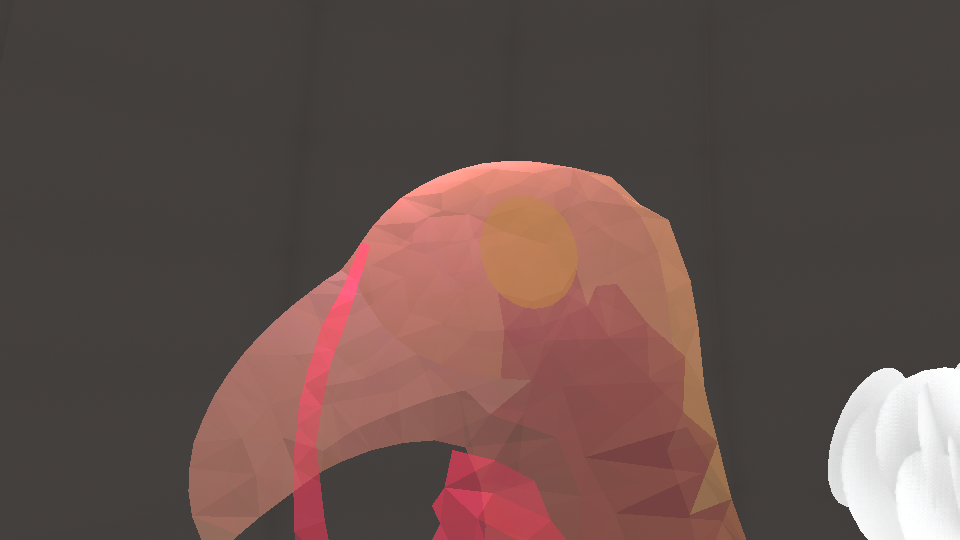

  │ 0:51 LogPython: X3DLAB: wrote gobbler3__EyeToEye__preview__key (1 files, 8.3 s)
  │ 0:51 LogPython: X3DLAB: job 4/4 gobbler3__Flywheel__preview__key: opening /Game/X3DLab/gobbler3/Map_gobbler3
  │ 0:51 LogGlobalStatus: Browse Started Browse: "/Game/X3DLab/gobbler3/Map_gobbler3??game=/Script/MovieRenderPipelineCore.MoviePipelineGameMode"
  │ 0:51 LogNet: Browse: /Game/X3DLab/gobbler3/Map_gobbler3??game=/Script/MovieRenderPipelineCore.MoviePipelineGameMode
  │ 0:51 LogLoad: LoadMap: /Game/X3DLab/gobbler3/Map_gobbler3??game=/Script/MovieRenderPipelineCore.MoviePipelineGameMode
  │ 0:51 LogWorld: BeginTearingDown for /Game/X3DLab/gobbler3/Map_gobbler3
  │ 0:51 LogStaticMesh: Display: Waiting on static mesh StaticMesh /Game/X3DLab/gobbler3/Shape_Sphere.Shape_Sphere being ready before playing
  │ 0:51 LogStaticMesh: Display: Waiting on static mesh StaticMesh /Game/X3DLab/gobbler3/Gobble_IndexedFaceSet_001.Gobble_IndexedFaceSet_001 being ready before playing
  │ 0:51 LogStaticMesh: Displa

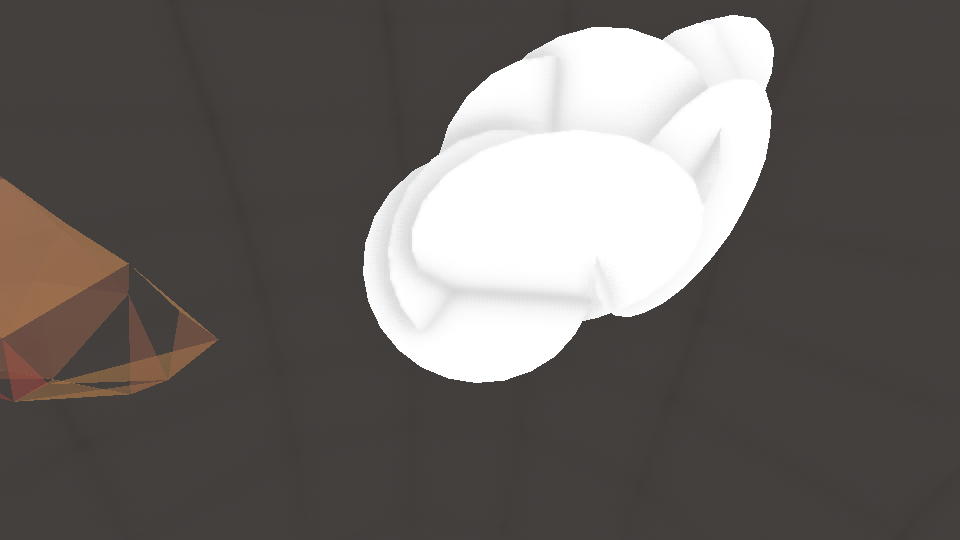

  │ 0:55 LogPython: X3DLAB: wrote gobbler3__Flywheel__preview__key (1 files, 4.2 s)
  │ 0:55 LogPython: X3DLAB: executor finished
  │ 0:55 LogWorld: BeginTearingDown for /Game/X3DLab/gobbler3/Map_gobbler3
  │ 0:55 LogSlate: Window 'X3DLab (64-bit Development SF_VULKAN_SM6) ' being destroyed
  │ 0:56 LogExit: Exiting.
■ render_gobbler3_preview_match_key: rc 0 in 1:00 · peak VRAM 4.9 GB, GPU up to 80%


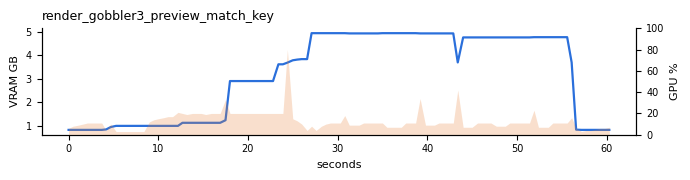

19:21:07 INFO  blender   render render ok (1.9 s)


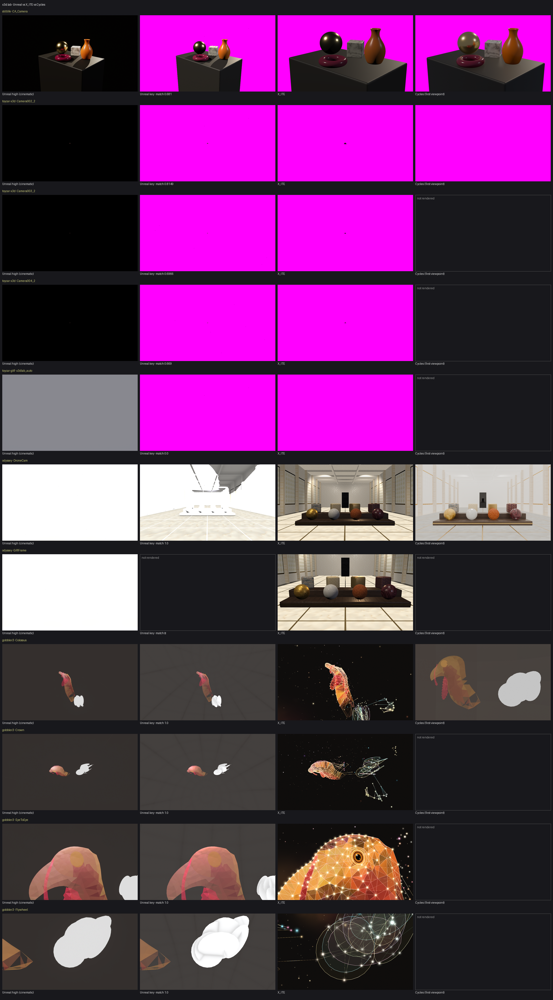

In [21]:
#@title 10 · Compare and contact sheet { display-mode: "form" }
CMP, SHEET = {}, None
if COMPARE and RND:
    from x3dlab import browser as xbrowser
    HB = xbrowser.start(gpu=True, viewport=(960, 540))
    print("X_ITE renderer:", HB.info.get("webgl") if hasattr(HB, "info") else "?")
    rows = []
    for n, out in RND.items():
        r = SCN[n]
        cams = [s["viewpoint"] for s in out["stills"]]
        key = pipeline.render(LAB, n, cams, "preview", PLAN["ladder"]["preview"], look="match", key=True, res_override=(960, 540))
        scene_dir = Path(r["fetch"]["main"]).parent
        main_name = Path(r["wrapper"]).name if r["kind"] == "gltf" else Path(r["fetch"]["main"]).name
        xi = engines.xite_views(HB, scene_dir, main_name, r["manifest"], size=(960, 540))
        cy = engines.cycles_first_view(BL, r["fetch"]["main"], WORK / "out" / ("cycles_%s.png" % n)) if (BL and r["kind"] == "x3d") else {}
        vps = {project.ue_name(x3dscene.viewpoint_name(v)): x3dscene.viewpoint_name(v) for v in r["manifest"]["viewpoints"]}
        for i, s in enumerate(out["stills"]):
            ks = next((k for k in key["stills"] if k["viewpoint"] == s["viewpoint"]), {})
            ue_key = Path(ks["png"]).read_bytes() if ks.get("png") else None
            x = (xi.get(vps.get(s["viewpoint"], s["viewpoint"])) or {}).get("png")
            j = compare.judge(x, ue_key, formats) if (x and ue_key) else {}
            jc = compare.judge(cy.get("png_key"), ue_key, formats) if (i == 0 and cy.get("png_key") and ue_key) else {}
            CMP["%s/%s" % (n, s["viewpoint"])] = {"xite": j, "cycles": jc}
            SC.add("10 compare", "%s/%s vs X_ITE" % (n, s["viewpoint"]), compare.verdict(j) if j else "SKIP",
                   ("match %.3f · IoU %.3f · SSIM %s · colour Δ %s%s" % (j["match"], j["iou"], j.get("ssim"), j.get("colour_delta"),
                    " (%s)" % j["colour_kind"] if j.get("colour_kind") else "")) if j.get("match") is not None else "a still is missing")
            rows.append({"label": "%s · %s" % (n, s["viewpoint"]), "cells": [
                ("Unreal %s (%s)" % (rung_name, LOOK), Path(s["png"]).read_bytes() if s.get("png") else None),
                ("Unreal key · match %s" % (j.get("match") if j else "–"), ue_key), ("X_ITE", x),
                ("Cycles (first viewpoint)", cy.get("png_key") if i == 0 else None)]})
    SHEET = compare.contact_sheet(rows, WORK / "out" / "contact_sheet.png")
    display(IPImage(filename=str(SHEET), width=1000))
    HB.close()
else:
    SC.add("10 compare", "engines compared", "SKIP", "COMPARE is off" if not COMPARE else "no Unreal stills")
CARD["compare"] = CMP

In [22]:
!pwd

/content


## 11 · Scorecard, run card, Drive

Everything in one table; the run card (JSON) records the GPU, driver, engine, settings, every attempt and every number above. Stills, the contact sheet, the logs and the run card are copied to `DRIVE_DIR/runs/<time>/`; the shader cache (DDC) goes to `DRIVE_DIR/cache/` so the next run skips most of the compile.

In [23]:
#@title 11 · Scorecard and save { display-mode: "form" }
RUN_ID = time.strftime("%Y%m%d-%H%M%S")
CARD.update(scorecard=SC.rows, summary=SC.counts(), attempts=LAB.attempts, run_id=RUN_ID, light_mapping=LAB.mapping.describe())
CARD_PATH = report.run_card(WORK / "out" / ("run_card_%s.json" % RUN_ID), CARD)
display(HTML("<div style='font:17px system-ui;margin:6px 0'><b>07 Unreal Fidelity on %s: %s</b></div>" % (HW["kind"], SC.word())))
display(HTML(SC.html()))
if Path(DRIVE_DIR).exists():
    import shutil
    dst = Path(DRIVE_DIR) / "runs" / RUN_ID
    for sub in ("stills", "logs", "scenes"):
        if (WORK / "out" / sub).exists():
            shutil.copytree(WORK / "out" / sub, dst / sub, dirs_exist_ok=True)
    for f in [CARD_PATH, SHEET]:
        if f:
            shutil.copy(f, dst)
    print("saved to", dst)
    if CACHE_DDC and ENGINE.get("version"):
        print("DDC to Drive:", pipeline.ddc_save(LAB, DRIVE_DIR))
print("run card:", CARD_PATH)

part,status,check,reason
3 tier,PASS,NVIDIA GPU present,"NVIDIA L4, 22 GB, driver 580.82.07"
3 tier,PASS,GPU in the capability table,L4: 3rd-gen RT cores
3 tier,PASS,free disk for the engine,235 GB free; zip + trimmed engine need about 90 GB (less when extracting straight from Drive)
3 tier,PASS,RAM,53 GB (Unreal recommends 32 GB; shader workers are capped by RAM)
4 Vulkan,PASS,NVIDIA Vulkan ICD present,/usr/share/vulkan/icd.d/nvidia_icd.json
4 Vulkan,PASS,user ue sees the NVIDIA device,NVIDIA L4 (Vulkan 1.4.312)
4 Vulkan,PASS,ray tracing decision,device lists VK_KHR_ray_tracing_pipeline + VK_KHR_acceleration_structure
4 Vulkan,PASS,nvoptix.bin (OptiX denoiser),/usr/share/nvidia/nvoptix.bin
5 engine,PASS,engine on local disk,Unreal 5.4.4 (changelist 35576357) from drive cache in 203 s
5 engine,PASS,engine version,"5.4.4 (asked for 5.4; 5.8.x is the current release, 5.9 a preview; before 5.4 Unreal on Linux has no Vulkan SM6, so no ray tracing)"


saved to /content/drive/MyDrive/x3dlab/unreal/runs/20261111-192131
DDC to Drive: {'archive': '/content/drive/MyDrive/x3dlab/unreal/cache/ddc.tar.zst', 'gb': 0.0}
run card: /content/x3due/out/run_card_20261111-192131.json


## 12 · What this run proved

In [24]:
#@title 12 · What this run proved { display-mode: "form" }
def said(part, check):
    r = next((r for r in SC.rows if r["part"] == part and r["check"] == check), None)
    return (r["status"], r["reason"]) if r else ("SKIP", "not run")
lines = []
s, why = said("6 start", "RHI is Vulkan on the NVIDIA GPU")
lines.append("**Unreal on Colab's GPU, headless:** %s: %s." % (s, why))
s, why = said("4 Vulkan", "ray tracing decision")
lines.append("**Ray tracing on this %s:** %s: %s." % (HW["kind"], s, why))
s, why = said("6 start", "one-time shader compile (cold start)")
lines.append("**First-run cost:** %s." % why)
ok_imp = [n for n, r in IMP.items() if r["report"].get("ok")]
lines.append("**Scenes imported:** %d of %d (%s)." % (len(ok_imp), len(IMP), ", ".join(ok_imp) or "none"))
ok_r = [n for n, r in RND.items() if any(s["png"] for s in r["stills"])]
lines.append("**Scenes rendered at %s:** %s." % (RUNG if RUNG != "auto" else "the auto rung", ", ".join(ok_r) or "none"))
if CMP:
    ms = [v["xite"]["match"] for v in CMP.values() if v.get("xite", {}).get("match") is not None]
    if ms:
        lines.append("**Silhouettes vs X_ITE:** median match %.3f over %d views (1.0 = same outline within 2 px)." % (sorted(ms)[len(ms) // 2], len(ms)))
if CALIB:
    lines.append("**Light units:** X3D intensity 1 → %s (calibrated K = %s)." % (LAB.mapping.describe()["rule"], CALIB.get("k_measured")))
c = SC.counts()
lines.append("**Scorecard:** %d PASS · %d WARN · %d FAIL · %d SKIP. Every FAIL row says why; the run card has the logs' key lines." % (c["PASS"], c["WARN"], c["FAIL"], c["SKIP"]))
display(HTML("<div style='font:14px system-ui;line-height:1.5'>" + "<br>".join(
    __import__("re").sub(r"\*\*(.+?)\*\*", r"<b>\1</b>", l) for l in lines) + "</div>"))

## Troubleshooting

| You see | Why | Do this |
|---|---|---|
| step 4: *no libnvidia-gl at exactly …* | the apt sources lack the driver's exact version | nothing to do safely; a different version would break CUDA. Try another runtime (the driver differs per GPU type) |
| step 4: user `ue` sees no NVIDIA device | the ICD was not unpacked, or `/dev/nvidia*` is not readable by `ue` | rerun step 4; `ls -l /dev/nvidia*` |
| step 5: *no engine found* | no zip or cache for `ENGINE_VERSION` in `DRIVE_DIR`, no `GHCR_TOKEN` | the message lists the zips it saw; pick one of those versions, or see *Your one-time step* |
| step 6: rc 139, call stack in `ShaderFormatVersion` | the project asked for a shader format this engine lacks (UE 5.2 has no Vulkan SM6 on Linux) | automatic: retried with Shader Model 5 and no ray tracing; or use 5.4+ |
| step 5: ghcr HTTP 401/403 | the token lacks `read:packages`, or the GitHub account is not linked to Epic / the EpicGames invitation is not accepted | fix the token or the link, rerun step 5 |
| step 5: *not enough local disk* | the trimmed engine does not fit | a runtime with a bigger disk (A100/G4), or remove old files in `/content` |
| step 6: `FAIL` *NullRHI* or *software Vulkan* | Unreal did not get the NVIDIA ICD | the run already pins `VK_ICD_FILENAMES` to NVIDIA's; check step 4's rows |
| step 6: `device_lost` | GPU crash; UE 5.8.0 had such reports on Linux | the notebook retries: async compute off → no ray tracing → Shader Model 5. Use 5.8.4 |
| step 6: *bindless* assertion | ray tracing on Vulkan needs bindless | retried automatically with `BindlessSupport=AllShaderTypes` |
| step 6 takes very long | the one-time shader compile; few vCPUs or little RAM make it slower | let it run; `CACHE_DDC` makes the next run fast |
| step 8: `api_misses` in the import report | a Python API name differs in this engine version | the import continues; tell the lab which names (they are in the run card) |
| step 9: no stills, log says *Movie Render* errors | MRQ did not start | the report says which job; `x3dlab_render.py` also has a `highresshot` mode (set `mode="highresshot"` in `pipeline.render`) |
| Colab disconnects | RAM exhausted | the watchdog stops Unreal at 94 % RAM; pick High-RAM, or fewer scenes |